# Исследовательский анализ данных (EDA): исходы цирроза печени

Исследуем данные соревнования [Kaggle Playground Series S3E26](https://www.kaggle.com/competitions/playground-series-s3e26): структуру и качество таблиц, распределения признаков и целевой переменной, а также связи между ними. Анализ будет дополняться по мере работы над проектом. Исходные файлы: train.csv, test.csv, sample_submission.csv.

## Команда проекта


|N|ФИО|Роль|
|---|---|---|
| 1. |Достовалов Александр Андреевич |	ML |
| 2. | Зарипов Данис Фиданович |	DA |
|3.| Воронкова Дарья |	PM |
|4.|Банникова Надежда Михайловна	| ML|
|5.|Шавлинский Станислав | PM |
|6.| Колодезев Егор	|DA|

## Описание столбцов датасета

| Название признака | Роль  | Тип | Описание | Единицы измерения |
| :--- | :--- | :--- | :--- | :--- |
| **ID** | ID | Integer | Технический идентификатор строки. | |
| **N_Days** | Feature | Integer | Число дней от включения в исследование до смерти, трансплантации или окончания наблюдения. |
| **Drug** | Feature | Categorical | Тип лекарства: D-penicillamine или Placebo | |
| **Age** | Feature | Integer | Возраст | дни |
| **Sex** | Feature | Categorical | M (мужской) или F (женский) | |
| **Ascites** | Feature | Categorical | Наличие асцита (жидкость в брюшной полости): N (Нет) или Y (Да) | |
| **Hepatomegaly** | Feature | Categorical | Наличие гепатомегалии (увеличения печени): N (Нет) или Y (Да) | |
| **Spiders** | Feature | Categorical | Наличие сосудистых звёздочек: N (Нет) или Y (Да) | |
| **Edema** | Feature | Categorical | Наличие отёков: N (нет отёков и нет диуретической терапии по поводу отёков), S (отёки есть, но без терапии диуретиками, либо отёки прошли на фоне диуретиков) или Y (отёки сохраняются, несмотря на терапию диуретиками) | |
| **Bilirubin** | Feature | Float | Билирубин сыворотки крови | мг/дл |
| **Cholesterol** | Feature | Integer | Холестерин сыворотки крови | мг/дл |
| **Albumin** | Feature | Float | Альбумин в сыворотке крови | г/дл |
| **Copper** | Feature | Integer | Медь в моче | мкг/сут |
| **Alk_Phos** | Feature | Float | Щелочная фосфатаза | Ед/л |
| **SGOT** | Feature | Float | Фермент SGOT (АСТ) | Ед/мл |
| **Tryglicerides** | Feature | Integer | Триглицериды | мг/дл |
| **Platelets** | Feature | Integer | Количество тромбоцитов | тыс./мкл |
| **Prothrombin** | Feature | Float | Протромбиновое время | сек |
| **Stage** | Feature | Categorical | Гистологическая стадия заболевания: 1–4 | |
| **Status** | Target | Categorical | Целевой исход: C — наблюдение завершено при живом пациенте; CL — наблюдение цензурировано из-за трансплантации; D — смерть.| |


## 1. Цель проекта и показатели эффективности

**Цель:** по табличным признакам пациента с циррозом предсказать вероятности трёх значений Status:

- C — пациент жив на момент N_Days (наблюдение цензурировано);
- CL — пациент жив после трансплантации печени;
- D — пациент умер к моменту N_Days.

Это **многоклассовая классификация**. Для каждой строки теста нужны три вероятности: Status_C, Status_CL, Status_D.

**Основная метрика соревнования — multiclass log loss** (чем меньше, тем лучше). Она оценивает качество *вероятностей* и сильно штрафует уверенные ошибочные прогнозы. Формула: $-\frac{1}{N}\sum_i\sum_j y_{ij}\log(p_{ij})$. При локальной проверке будем использовать стратифицированную кросс-валидацию и считать средний log loss со стандартным отклонением между фолдами. Предсказания для каждого пациента должны суммироваться до 1.

**Дополнительные диагностические метрики:** accuracy, macro F1, recall по каждому классу и матрица ошибок. Они помогают понять, как модель работает с редким CL, но не заменяют основную метрику. Для начала полезно сравнить будущие модели с базовым прогнозом по частотам классов на обучающей части каждого фолда.

**Ограничение постановки:** N_Days отражает длительность наблюдения. Признак дан в тесте Kaggle, но для реального прогноза на момент первичного осмотра его доступность нужно отдельно обосновать. Данные синтетические, результаты соревнования нельзя напрямую трактовать как клиническую точность.

## 2. Загрузка данных и первичный осмотр

### 2.1 Загрузка данных

Загружаем исходные CSV без изменения значений. id — идентификатор строки, целевой признак Status есть только в train. Пути ищутся относительно расположения ноутбука или текущей рабочей папки.


In [1]:
!pip install phik optuna-integration[sklearn]
!pip install -q optuna


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik
import optuna
from scipy.stats import loguniform, uniform
from sklearn.base import clone, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, MinMaxScaler, RobustScaler, FunctionTransformer
from sklearn.metrics import accuracy_score, f1_score, log_loss, recall_score, ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import train_test_split, StratifiedKFold, HalvingRandomSearchCV, GridSearchCV, RandomizedSearchCV, HalvingGridSearchCV
from optuna.distributions import FloatDistribution, CategoricalDistribution
from optuna_integration.sklearn import OptunaSearchCV

import warnings
warnings.filterwarnings('ignore')


In [3]:
# Глобальные настройки отображения
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})

# Глобальные константы
CLASSES = ['C', 'CL', 'D']
RANDOM_STATE = 42

# Публичные CSV из основной ветки GitHub: работает в Google Colab без клонирования репозитория.
base_url = "https://raw.githubusercontent.com/voronkovadarya74-cell/liver-cirrhosis-prediction/main/data/raw/"
train = pd.read_csv(base_url + "train.csv")
test = pd.read_csv(base_url + "test.csv")
submission_example = pd.read_csv(base_url + "sample_submission.csv")

print(f"train: {train.shape[0]} строк × {train.shape[1]} столбцов")
print(f"test: {test.shape[0]} строк × {test.shape[1]} столбцов")
print(f"sample_submission: {submission_example.shape[0]} строк × {submission_example.shape[1]} столбца")

train: 7905 строк × 20 столбцов
test: 5271 строк × 19 столбцов
sample_submission: 5271 строк × 4 столбца


### 2.2 Первичный осмотр датасета


In [4]:
train.head()

,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
0,0,999,D-penicillamine,21532,M,N,N,N,N,2.30,316.00,3.35,172.00,1601.00,179.80,63.00,394.00,9.70,3.00,D
1,1,2574,Placebo,19237,F,N,N,N,N,0.90,364.00,3.54,63.00,1440.00,134.85,88.00,361.00,11.00,3.00,C
2,2,3428,Placebo,13727,F,N,Y,Y,Y,3.30,299.00,3.55,131.00,1029.00,119.35,50.00,199.00,11.70,4.00,D
3,3,2576,Placebo,18460,F,N,N,N,N,0.60,256.00,3.50,58.00,1653.00,71.30,96.00,269.00,10.70,3.00,C
4,4,788,Placebo,16658,F,N,Y,N,N,1.10,346.00,3.65,63.00,1181.00,125.55,96.00,298.00,10.60,4.00,C


In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 7905 entries, 0 to 7904
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             7905 non-null   int64  
 1   N_Days         7905 non-null   int64  
 2   Drug           7905 non-null   str    
 3   Age            7905 non-null   int64  
 4   Sex            7905 non-null   str    
 5   Ascites        7905 non-null   str    
 6   Hepatomegaly   7905 non-null   str    
 7   Spiders        7905 non-null   str    
 8   Edema          7905 non-null   str    
 9   Bilirubin      7905 non-null   float64
 10  Cholesterol    7905 non-null   float64
 11  Albumin        7905 non-null   float64
 12  Copper         7905 non-null   float64
 13  Alk_Phos       7905 non-null   float64
 14  SGOT           7905 non-null   float64
 15  Tryglicerides  7905 non-null   float64
 16  Platelets      7905 non-null   float64
 17  Prothrombin    7905 non-null   float64
 18  Stage          7905

Исходя из описания признаков датасета и фактически автоматически определенных типов признаков, проведем оптимизацию - Категориальные признаки переведем в category, у числовых снизим максимально размерность, и переведем float в int согласно описанию.


### 2.3 Оптимизация

In [6]:
def optimize_df(df, name=None):
  memory_before = df.memory_usage(deep=True).sum() / 1024**2
  print(f"💾 Память {name if name else ''} до: {memory_before:.2f} MB")
  int_cols = ['Stage', 'Cholesterol', 'Copper', 'Platelets', 'Tryglicerides']
  float_cols = set(df.select_dtypes(include='number').columns) - set(int_cols)

  for col in int_cols:
      if col in df.columns:
          df[col] = pd.to_numeric(df[col], downcast='integer')

  for col in float_cols:
      if col in df.columns:
          df[col] = pd.to_numeric(df[col], downcast='float')

  cat_candidates = list(df.select_dtypes(exclude='number').columns)
  for col in cat_candidates:
      if col in df.columns:
          unique_ratio = df[col].nunique() / len(df)
          if unique_ratio < 0.2:
              df[col] = df[col].astype('category')
              print(f"📦 {col} → category (уникальность: {unique_ratio:.1%})")

  # Замер памяти после оптимизации
  memory_after = df.memory_usage(deep=True).sum() / 1024**2
  print(f"\n💾 Память {name if name else ''} после: {memory_after:.2f} MB")
  print(f"📉 Экономия: {(1 - memory_after/memory_before)*100:.1f}%")

In [7]:
optimize_df(train, 'train')

💾 Память train до: 3.50 MB
📦 Drug → category (уникальность: 0.0%)
📦 Sex → category (уникальность: 0.0%)
📦 Ascites → category (уникальность: 0.0%)
📦 Hepatomegaly → category (уникальность: 0.0%)
📦 Spiders → category (уникальность: 0.0%)
📦 Edema → category (уникальность: 0.0%)
📦 Status → category (уникальность: 0.0%)

💾 Память train после: 0.36 MB
📉 Экономия: 89.6%


In [8]:
optimize_df(test, 'test')

💾 Память test до: 2.08 MB
📦 Drug → category (уникальность: 0.0%)
📦 Sex → category (уникальность: 0.0%)
📦 Ascites → category (уникальность: 0.0%)
📦 Hepatomegaly → category (уникальность: 0.0%)
📦 Spiders → category (уникальность: 0.0%)
📦 Edema → category (уникальность: 0.1%)

💾 Память test после: 0.27 MB
📉 Экономия: 87.2%


### 2.4 Описательная статистика

Для числовых признаков смотрим количество значений, среднее, стандартное отклонение, квартили и крайние значения. Для категориальных — количество уникальных значений, самый частый вариант и его частоту. id — технический идентификатор, поэтому исключаем его из статистики признаков.

In [9]:
numeric_features = train.select_dtypes(include="number").drop(columns="id")
numeric_features.describe().T

,count,mean,std,min,25%,50%,75%,max
N_Days,7905.00,2030.17,1094.23,41.00,1230.00,1831.00,2689.00,4795.00
Age,7905.00,18373.14,3679.96,9598.00,15574.00,18713.00,20684.00,28650.00
Bilirubin,7905.00,2.59,3.81,0.30,0.70,1.10,3.00,28.00
Cholesterol,7905.00,350.56,195.38,120.00,248.00,298.00,390.00,1775.00
Albumin,7905.00,3.55,0.35,1.96,3.35,3.58,3.77,4.64
Copper,7905.00,83.90,75.90,4.00,39.00,63.00,102.00,588.00
Alk_Phos,7905.00,1816.75,1903.75,289.00,834.00,1181.00,1857.00,13862.40
SGOT,7905.00,114.60,48.79,26.35,75.95,108.50,137.95,457.25
Tryglicerides,7905.00,115.34,52.53,33.00,84.00,104.00,139.00,598.00
Platelets,7905.00,265.23,87.47,62.00,211.00,265.00,316.00,563.00


Отрицательных или нулевых значений в возрасте, длительности наблюдения и лабораторных показателях в train не обнаружено. Это исключает часть очевидных ошибок ввода, однако само по себе не подтверждает клиническую допустимость всех значений. Экстремальные наблюдения дополнительно рассмотрим по распределениям и правилу IQR.

In [10]:
categorical_features = train.select_dtypes(exclude="number")
categorical_features.describe().T

,count,unique,top,freq
Drug,7905,2,Placebo,4010
Sex,7905,2,F,7336
Ascites,7905,2,N,7525
Hepatomegaly,7905,2,Y,4042
Spiders,7905,2,N,5966
Edema,7905,3,N,7161
Status,7905,3,C,4965


Провеим соотвествие описанию категориальных признаков. Поскольку Stage является так же категориальным, включим его

In [11]:
columns = list(categorical_features.columns) + ['Stage']
for col in train[columns]:
  print(f'{col} - ', train[col].unique())

Drug -  ['D-penicillamine', 'Placebo']
Categories (2, str): ['D-penicillamine', 'Placebo']
Sex -  ['M', 'F']
Categories (2, str): ['F', 'M']
Ascites -  ['N', 'Y']
Categories (2, str): ['N', 'Y']
Hepatomegaly -  ['N', 'Y']
Categories (2, str): ['N', 'Y']
Spiders -  ['N', 'Y']
Categories (2, str): ['N', 'Y']
Edema -  ['N', 'Y', 'S']
Categories (3, str): ['N', 'S', 'Y']
Status -  ['D', 'C', 'CL']
Categories (3, str): ['C', 'CL', 'D']
Stage -  [3 4 2 1]


### 2.5 Структура train и test

Проверяем, что тест отличается от обучающей выборки только отсутствием целевой переменной, а идентификаторы уникальны.

In [12]:
feature_columns = [column for column in train.columns if column != "Status"]
print("Признаки train и столбцы test совпадают:", feature_columns == list(test.columns))
print("Уникальные id в train:", train["id"].is_unique)
print("Уникальные id в test:", test["id"].is_unique)
print("Пересечение id train/test:", len(set(train["id"]) & set(test["id"])))

Признаки train и столбцы test совпадают: True
Уникальные id в train: True
Уникальные id в test: True
Пересечение id train/test: 0


### Выводы по описательной статистике:

* Очевидных ошибок ввода данных нет
* Часть числовых признаков выходят за рамки  1,5 × IQR и требуют аналаза выбросов

## 3. Анализ и обработка пропусков

Сначала считаем настоящие NaN/None. Отдельно проверяем пустые и состоящие из пробелов строки в текстовых столбцах: pandas может не считать их пропусками. Проверки проводим на train и test по отдельности.

In [13]:
def missing_report(frame):
    # В одном отчёте объединяем стандартные пропуски и пустой текст.
    text_columns = frame.select_dtypes(include=["object", "string"]).columns
    missing_mask = frame.isna().copy()
    for column in text_columns:
        missing_mask[column] |= frame[column].astype("string").str.strip().eq("").fillna(False)
    report = pd.DataFrame({
        "Пропусков": missing_mask.sum(),
        "Доля, %": missing_mask.mean().mul(100).round(2),
    })
    return report.sort_values("Пропусков", ascending=False), int(missing_mask.any(axis=1).sum())

for name, frame in [("train", train), ("test", test)]:
    report, rows_with_missing = missing_report(frame)
    print(f"{name}: строк с хотя бы одним пропуском — {rows_with_missing}; всего пропусков — {report['Пропусков'].sum()}")
    print(report.to_string())

train: строк с хотя бы одним пропуском — 0; всего пропусков — 0
               Пропусков  Доля, %
id                     0     0.00
N_Days                 0     0.00
Drug                   0     0.00
Age                    0     0.00
Sex                    0     0.00
Ascites                0     0.00
Hepatomegaly           0     0.00
Spiders                0     0.00
Edema                  0     0.00
Bilirubin              0     0.00
Cholesterol            0     0.00
Albumin                0     0.00
Copper                 0     0.00
Alk_Phos               0     0.00
SGOT                   0     0.00
Tryglicerides          0     0.00
Platelets              0     0.00
Prothrombin            0     0.00
Stage                  0     0.00
Status                 0     0.00
test: строк с хотя бы одним пропуском — 0; всего пропусков — 0
               Пропусков  Доля, %
id                     0     0.00
N_Days                 0     0.00
Drug                   0     0.00
Age                    

### Решение по обработке

В текущих файлах пропусков и пустых текстовых значений нет, поэтому удаление строк или заполнение значений **не требуется**. Исходные CSV сохраняем без изменений. Если пропуски появятся в новых данных, способ заполнения нужно выбирать по смыслу признака и обучать его только на тренировочной части каждого фолда, чтобы не допустить утечки информации.

## 4. Поиск аномалий и обработка выбросов

### 4.1 Анализ выбросов

In [14]:
# Функция для получения точных границ выбросов по IQR
def get_margins_from_col(df):
  iqr = df.quantile(0.75) - df.quantile(0.25)
  left =  max(df.quantile(0.25) - 1.5 * iqr, df.min())
  right = min(df.quantile(0.75) + 1.5 * iqr, df.max())
  return (left, right)

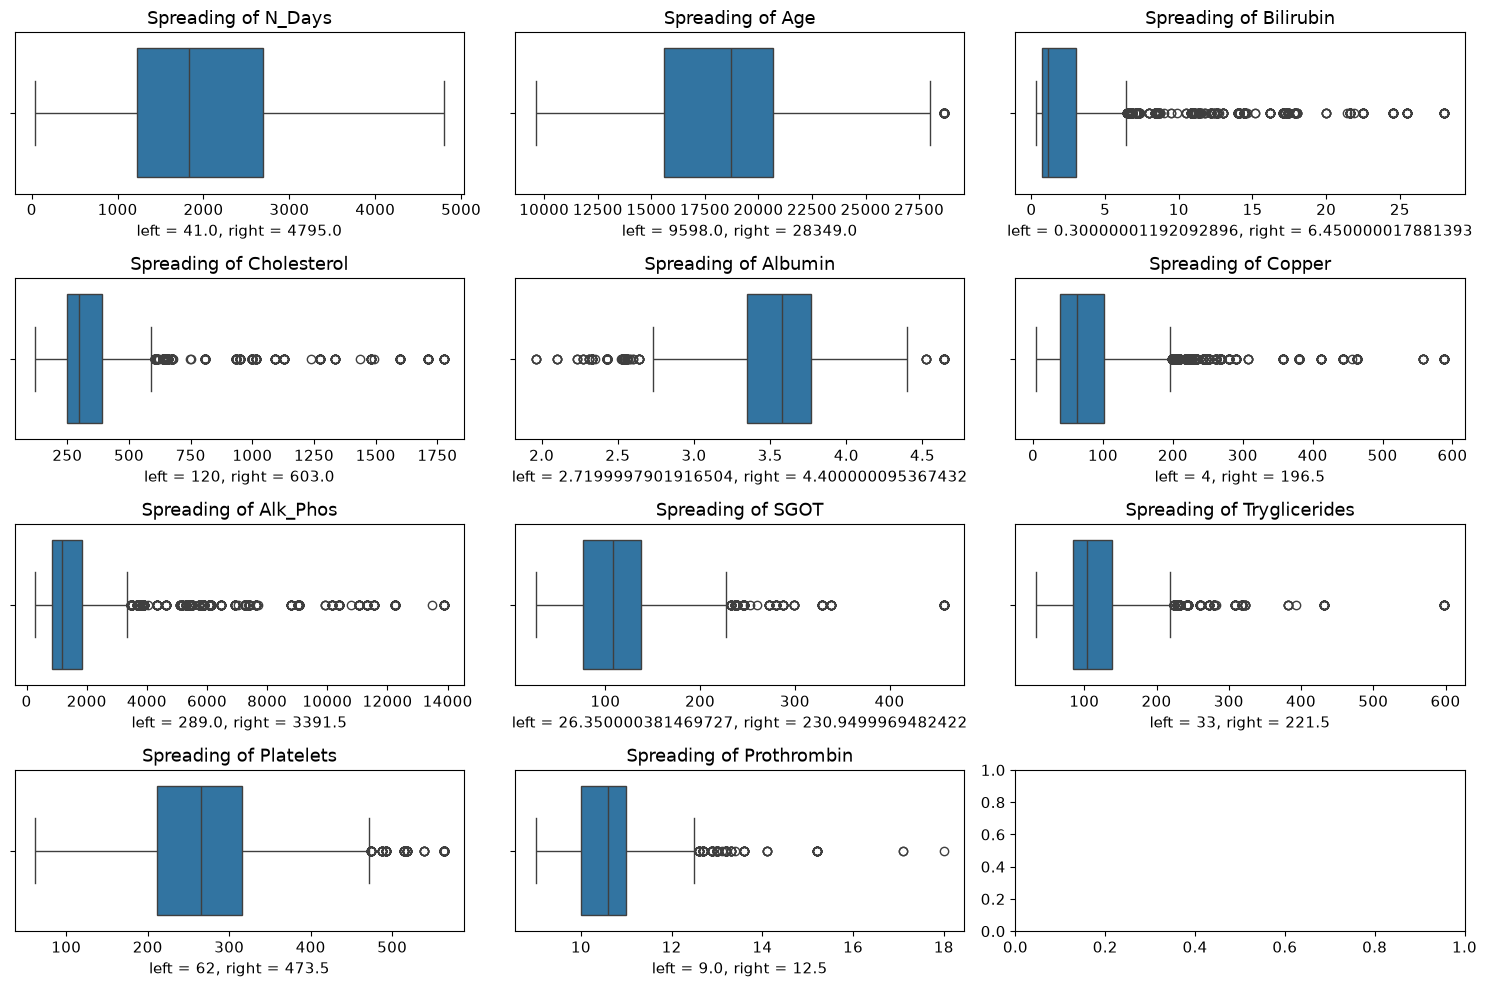

In [15]:
numeric_cols = [
    c for c in train.select_dtypes(include="number").columns
    if c not in {"id", "Stage"}
]

fig, axes = plt.subplots(int(np.ceil(len(numeric_cols)/3)),3, figsize=(15,10))
axes = axes.flatten()
for i, col in enumerate(train[numeric_cols]):
  left, right = get_margins_from_col(train[col])

  sns.boxplot(data=train, x=col, ax=axes[i])
  axes[i].set_title(f'Spreading of {col}')
  axes[i].set_xlabel(f'left = {left}, right = {right}')
plt.tight_layout()
plt.show()

* У ряда лабораторных показателей есть значения далеко за пределами основной массы наблюдений.
* У Bilirubin, Cholesterol, Alk_Phos, Copper и Tryglicerides выражена правая асимметрия: средние выше медиан, распределения имеют длинные правые хвосты.
* Возраст в исходном файле указан в днях; распределение возраста в годах показано ниже в разделе 5.
* Albumin имеет левую асимметрию. Связь низких значений с исходом рассмотрим отдельно.
* По правилу 1,5 × IQR выше верхней границы находятся 792 наблюдения для Alk_Phos и 789 для Bilirubin. Само правило помечает статистически редкие значения, но не доказывает ошибку измерения.
* Экстремальные значения пока сохраняем: оснований автоматически удалять их по одному лишь boxplot нет.

Гипотеза - отклонения связаны с тяжелым состоянием пациента, обусловленым декомпенсацией печени. Тогда большая часть пациентов с такими экстремальными значениями будет находится в самом негативном исходе - класс D.

Проверяем гипотезу, что отклонения связаны с тяжелым состоянием пациента и не являются выбросами

In [16]:
test_df = train[numeric_cols].drop(columns=['N_Days', 'Age'])
results = []

for col in test_df:
  left, right = get_margins_from_col(train[col])
  filtered_df = train[train[col] > right]
  counts =  filtered_df.groupby('Status', observed=False).size().reindex(['C', 'CL', 'D'], fill_value=0)
  counts_sum = counts.sum()

  results.append({
      'Feature': col,
      'Total_patients': counts_sum,
      'C': counts['C'],
      'C_percent': round((counts['C'] / counts_sum * 100), 1) if counts_sum > 0 else 0,
      'CL': counts['CL'],
      'CL_percent': round((counts['CL'] / counts_sum * 100), 1) if counts_sum > 0 else 0,
      'D': counts['D'],
      'D_percent': round((counts['D'] / counts_sum * 100), 1) if counts_sum > 0 else 0
  })

results = pd.DataFrame(results)
display(results.sort_values(by='D_percent', ascending=False))


,Feature,Total_patients,C,C_percent,CL,CL_percent,D,D_percent
0,Bilirubin,789,137,17.40,17,2.20,635,80.50
8,Prothrombin,173,32,18.50,2,1.20,139,80.30
3,Copper,655,132,20.20,17,2.60,506,77.30
1,Cholesterol,502,169,33.70,19,3.80,314,62.50
6,Tryglicerides,267,90,33.70,12,4.50,165,61.80
5,SGOT,146,58,39.70,4,2.70,84,57.50
4,Alk_Phos,792,358,45.20,25,3.20,409,51.60
7,Platelets,114,67,58.80,2,1.80,45,39.50
2,Albumin,25,25,100.00,0,0.00,0,0.00


 Из анализа правых выбросов уровни биохимических показателей действительно показывают более тяжелое состояние у таких пациентов на основании целевой переменной. Однако показатель Albumin для правых выбросов отображает противоположную картину

Проверим выбросы левые выбросы

In [17]:
test_df = train[numeric_cols].drop(columns=['N_Days', 'Age'])
results = []

for col in test_df:
  left, right = get_margins_from_col(train[col])
  filtered_df = train[train[col] < left]
  counts =  filtered_df.groupby('Status', observed=False).size().reindex(['C', 'CL', 'D'], fill_value=0)
  counts_sum = counts.sum()

  results.append({
      'Feature': col,
      'Total_patients': counts_sum,
      'C': counts['C'],
      'C_percent': round((counts['C'] / counts_sum * 100), 1) if counts_sum > 0 else 0,
      'CL': counts['CL'],
      'CL_percent': round((counts['CL'] / counts_sum * 100), 1) if counts_sum > 0 else 0,
      'D': counts['D'],
      'D_percent': round((counts['D'] / counts_sum * 100), 1) if counts_sum > 0 else 0
  })

results = pd.DataFrame(results)
display(results.sort_values(by='D_percent', ascending=False))

,Feature,Total_patients,C,C_percent,CL,CL_percent,D,D_percent
2,Albumin,153,12,7.80,1,0.70,140,91.50
0,Bilirubin,0,0,0.00,0,0.00,0,0.00
1,Cholesterol,0,0,0.00,0,0.00,0,0.00
3,Copper,0,0,0.00,0,0.00,0,0.00
4,Alk_Phos,0,0,0.00,0,0.00,0,0.00
5,SGOT,0,0,0.00,0,0.00,0,0.00
6,Tryglicerides,0,0,0.00,0,0.00,0,0.00
7,Platelets,0,0,0.00,0,0.00,0,0.00
8,Prothrombin,0,0,0.00,0,0.00,0,0.00


Из анализа левых выбросов Albumin действительно показывает большую долю класса D, что свидетельствует о тяжести состояния таких пациентов. Требуется перекрестная проверка - при низком Альбумине и высоких других биохимических показателях, целевой признак в подавляющем большинстве случаев должен быть - D

In [18]:
alb_left, _ = get_margins_from_col(test_df["Albumin"])
low_alb_mask = test_df["Albumin"] < alb_left
total_low_alb = int(low_alb_mask.sum())


print(f"Всего пациентов с низким Albumin (< {alb_left:.2f}): {total_low_alb}\n")

right_outlier_cols = [
    "Bilirubin", "Prothrombin", "Copper", "Cholesterol",
    "Tryglicerides", "SGOT", "Alk_Phos", "Platelets"
]

cross_check_results = []

for col in right_outlier_cols:
    _, right_margin = get_margins_from_col(test_df[col])

    # Пересечение
    combined_mask = low_alb_mask & (train[col] > right_margin)
    subset = train[combined_mask]

    counts = (
        subset.groupby("Status", observed=False)
        .size()
        .reindex(["C", "CL", "D"], fill_value=0)
    )
    group_total = int(counts.sum())

    cross_check_results.append({
        "Показатель > IQR": col,
        "Пациентов в пересечении": group_total,
        "Доля от низкого Albumin, %": round(group_total / total_low_alb * 100, 1) if total_low_alb > 0 else 0.0,
        "C": int(counts["C"]),
        "C, %": round(counts["C"] / group_total * 100, 1) if group_total > 0 else 0.0,
        "CL": int(counts["CL"]),
        "CL, %": round(counts["CL"] / group_total * 100, 1) if group_total > 0 else 0.0,
        "D": int(counts["D"]),
        "D, %": round(counts["D"] / group_total * 100, 1) if group_total > 0 else 0.0,
    })

cross_check_df = pd.DataFrame(cross_check_results).sort_values(
    by=["Пациентов в пересечении", "D, %"],
    ascending=False
)
cross_check_df


Всего пациентов с низким Albumin (< 2.72): 153



,Показатель > IQR,Пациентов в пересечении,"Доля от низкого Albumin, %",C,"C, %",CL,"CL, %",D,"D, %"
0,Bilirubin,86,56.20,3,3.50,0,0.00,83,96.50
6,Alk_Phos,30,19.60,1,3.30,1,3.30,28,93.30
2,Copper,28,18.30,1,3.60,0,0.00,27,96.40
1,Prothrombin,14,9.20,0,0.00,0,0.00,14,100.00
3,Cholesterol,10,6.50,1,10.00,0,0.00,9,90.00
4,Tryglicerides,7,4.60,0,0.00,0,0.00,7,100.00
5,SGOT,5,3.30,0,0.00,0,0.00,5,100.00
7,Platelets,0,0.00,0,0.00,0,0.00,0,0.00


Из кросс-проверки мы видим, четкую взаимосвязь между экстремальных параметров и статусом пациента, а значит эти данные являются отображением тяжести состояния , а не выбросами. Оставляем их в датасете

Дополнительно проверим, что при пересечении нескольких случайно взятых параметрах с выбросами найдутся такие пациенты, и понятно тем меньше, чем больше фильтраций

In [19]:
train[
    (train['Albumin'] < get_margins_from_col(train['Albumin'])[0])
    & (train['Bilirubin'] > get_margins_from_col(train['Bilirubin'])[1])
    & (train['Prothrombin'] > get_margins_from_col(train['Prothrombin'])[1])
    & (train['Copper'] > get_margins_from_col(train['Copper'])[1])
]

,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
3197,3197.00,1478.00,D-penicillamine,15177.00,F,Y,N,Y,Y,17.10,151,2.54,207,1257.00,119.35,70,139,12.70,4,D
4598,4598.00,191.00,D-penicillamine,21483.00,F,Y,Y,Y,Y,17.90,243,2.33,220,3196.00,155.00,154,165,12.60,4,D
7642,7642.00,264.00,D-penicillamine,20555.00,F,N,Y,Y,Y,17.40,175,2.10,220,705.00,338.00,229,62,12.90,4,D


### 4.2 Анализ дубликатов

In [20]:
train.duplicated().sum()

np.int64(0)

Поскольку id есть у всех и уникально, уберем его и проверим частичные дубликаты

In [21]:
train.drop(columns=['id']).duplicated().sum()

np.int64(0)

Удалим колонку id поскольку она является техническим полем и не несет никакой полезной информации

In [22]:
train_clear = train.drop(columns=['id']).reset_index(drop=True)
train_clear.info()

<class 'pandas.DataFrame'>
RangeIndex: 7905 entries, 0 to 7904
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   N_Days         7905 non-null   float32 
 1   Drug           7905 non-null   category
 2   Age            7905 non-null   float32 
 3   Sex            7905 non-null   category
 4   Ascites        7905 non-null   category
 5   Hepatomegaly   7905 non-null   category
 6   Spiders        7905 non-null   category
 7   Edema          7905 non-null   category
 8   Bilirubin      7905 non-null   float32 
 9   Cholesterol    7905 non-null   int16   
 10  Albumin        7905 non-null   float32 
 11  Copper         7905 non-null   int16   
 12  Alk_Phos       7905 non-null   float32 
 13  SGOT           7905 non-null   float32 
 14  Tryglicerides  7905 non-null   int16   
 15  Platelets      7905 non-null   int16   
 16  Prothrombin    7905 non-null   float32 
 17  Stage          7905 non-null   int8    
 18 

Проверка показала, что в датасете присутствует ровно 0 дубликатов. Все наблюдения в таблице уникальны. Технический столбец id не несет аналитической нагрузки, поэтому для дальнейшего анализа будет создан датасет train_clear — копию обучающей таблицы без технического идентификатора id. Исходные train и test сохраняем без изменений.

## 5. Анализ распределения признаков

### 5.1 Анализ категориальных признаков

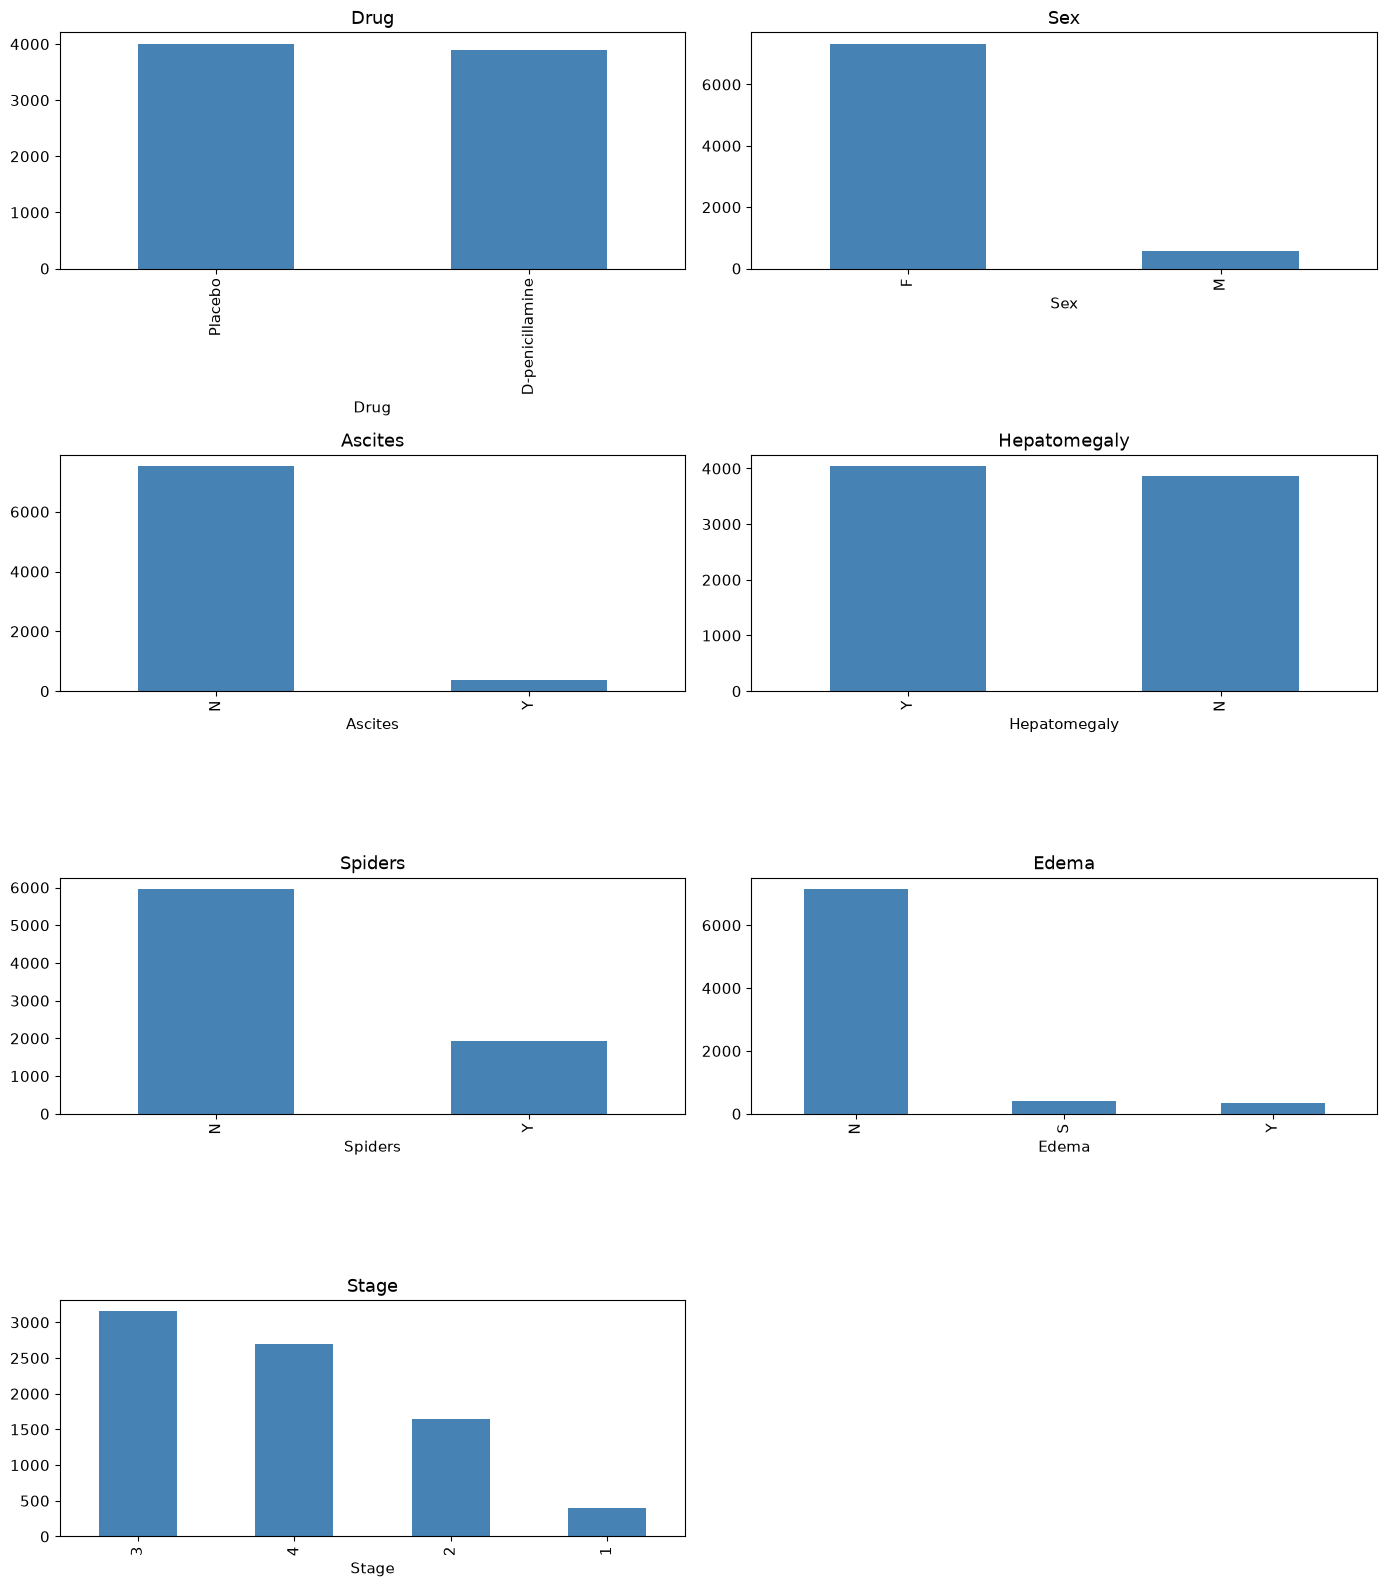

,Признак,Распределение долей
0,Drug,"Placebo: 50.73%, D-penicillamine: 49.27%"
1,Sex,"F: 92.8%, M: 7.2%"
2,Ascites,"N: 95.19%, Y: 4.81%"
3,Hepatomegaly,"Y: 51.13%, N: 48.87%"
4,Spiders,"N: 75.47%, Y: 24.53%"
5,Edema,"N: 90.59%, S: 5.05%, Y: 4.36%"
6,Stage,"3: 39.89%, 4: 34.19%, 2: 20.9%, 1: 5.02%"


In [23]:
CAT_FEATS = ["Drug", "Sex", "Ascites", "Hepatomegaly", "Spiders", "Edema", "Stage"]

n = len(CAT_FEATS)
fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(14, 4 * ((n + 1) // 2)))
axes = axes.flatten()
for ax, col in zip(axes, CAT_FEATS):
    train_clear[col].value_counts().plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(col)
for ax in axes[n:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

cat_shares = []
for col in CAT_FEATS:
    shares = (train_clear[col].value_counts(normalize=True) * 100).round(2)
    dist_str = ", ".join([f"{k}: {v}%" for k, v in shares.items()])
    cat_shares.append({"Признак": col, "Распределение долей": dist_str})

display(pd.DataFrame(cat_shares))

* `Drug`: доли плацебо и D-пеницилламина близки (50,7% и 49,3%). По одному распределению лечения нельзя судить о его связи с исходом.
* `Sex`: женщины составляют 92,8% выборки, мужчины — 7,2%. Из-за небольшой мужской подгруппы качество модели для неё стоит оценивать отдельно.
* `Ascites=Y` встречается у 4,8% пациентов. Связь этого признака с исходом проверим в двумерном анализе и при моделировании.
* `Hepatomegaly=Y` встречается у 51,1%, `Spiders=Y` — у 24,5% пациентов.
* `Edema` имеет три уровня: N — 90,6%, S — 5,0%, Y — 4,4%. Способ кодирования следует сравнить при моделировании.
* `Stage` принимает значения от 1 до 4 и описывает порядковую стадию заболевания.

### 5.2 Анализ числовых признаков

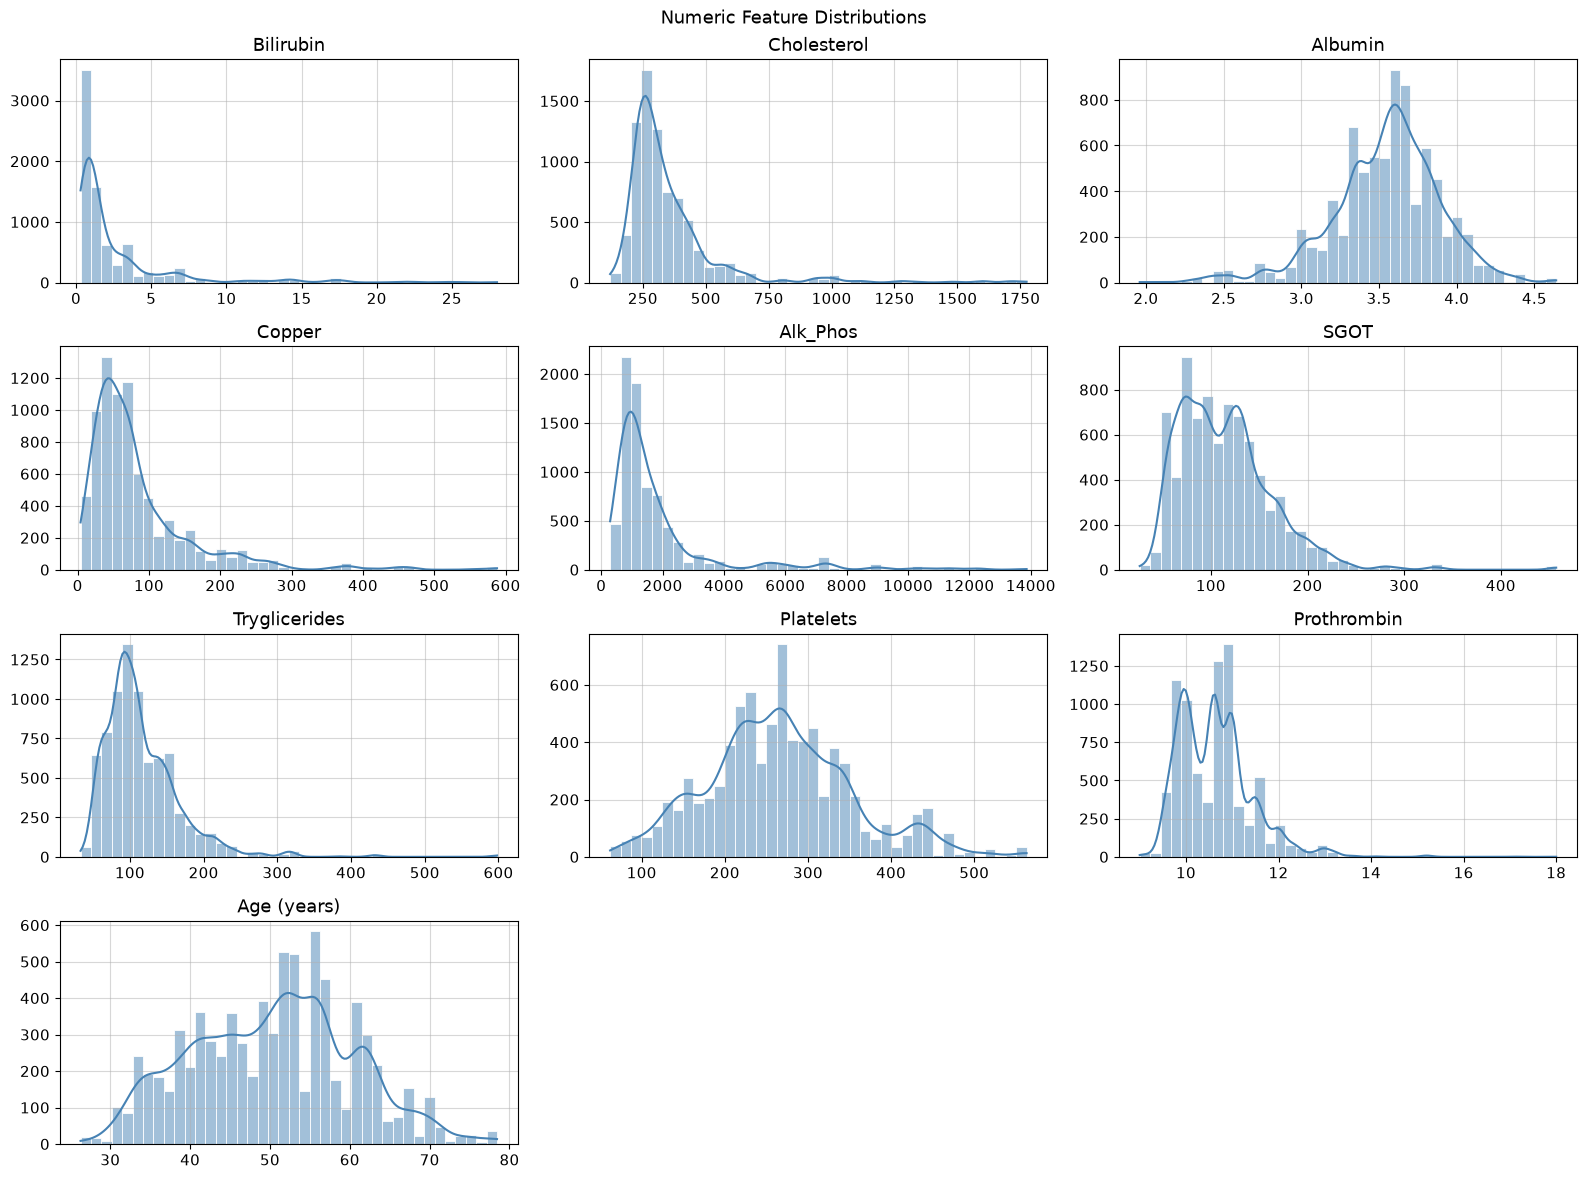

In [24]:
# Числовые признаки: гистограмма и сглаженная линия распределения (KDE).
clean_num_feats = [
    column for column in train_clear.select_dtypes(include="number").columns
    if column not in {"Stage", "Age", "N_Days"}
]
hist_data = train_clear[clean_num_feats].copy()
# Возраст переводим в годы только для графика, не изменяя исходный Age.
hist_data["Age (years)"] = train_clear["Age"] / 365.25

columns = hist_data.columns
fig, axes = plt.subplots(4, 3, figsize=(16, 12))
for ax, column in zip(axes.flat, columns):
    sns.histplot(hist_data[column], bins=40, kde=True, ax=ax,
                 color="steelblue", edgecolor="white")
    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(True, alpha=0.5)
for ax in list(axes.flat)[len(columns):]:
    ax.set_visible(False)
fig.suptitle("Numeric Feature Distributions")
plt.tight_layout()
plt.show()

* У Bilirubin, Cholesterol, Alk_Phos, Copper и Tryglicerides видны длинные правые хвосты. Для моделирования целесообразно масштабирование этих признаков.
* Возраст после перевода из дней в годы лежит примерно в диапазоне 26–78 лет. Гистограмма показывает распределение непосредственно, без округления возраста до целых лет.

## 6. Исследование баланса целевой переменной Status

### 6.1 Значения целевой переменной и верификация данных

**Цель:** определить численность и доли классов исходов, оценить дисбаланс и сформулировать рекомендации по разбиению данных и оценке моделей.

Данные соревнования синтетические: доли характеризуют эту выборку, а не клиническую популяцию.

| Класс | Интерпретация по описанию соревнования |
|---|---|
| C | Пациент жив на момент N_Days; наблюдение цензурировано |
| CL | Пациент жив на момент N_Days после трансплантации печени |
| D | Пациент умер к моменту N_Days |

Класс C не означает выздоровление или гарантированное дальнейшее выживание. Статусы относятся к сроку наблюдения N_Days и не задают единый горизонт прогноза, например один год.

Проверяем пропуски и допустимые значения. Неожиданные метки не исправляются автоматически: сначала нужно установить их происхождение. При проблемах расчёт останавливается, чтобы не получить неверные доли.

In [25]:
target = train_clear['Status']
missing = int(target.isna().sum())
unexpected = target[target.notna() & ~target.isin(CLASSES)]
print('Тип данных:', target.dtype)
print('Уникальные значения:', target.unique().tolist())
print('Пропуски:', missing)
print('Неожиданные метки:', unexpected.unique().tolist())
if len(train) == 0:
    raise ValueError('Выборка пуста.')
if missing or len(unexpected):
    raise ValueError('Сначала разберите пропуски или неожиданные метки Status.')
if not set(CLASSES).issubset(set(target)):
    raise ValueError('Один из трёх ожидаемых классов отсутствует.')
print('Проверка пройдена: все статусы заполнены и соответствуют описанию.')

Тип данных: category
Уникальные значения: ['D', 'C', 'CL']
Пропуски: 0
Неожиданные метки: []
Проверка пройдена: все статусы заполнены и соответствуют описанию.


### 6.2 Численность и доли классов
Доля класса = число его наблюдений / общее число наблюдений × 100%. Порядок классов фиксирован для удобного сравнения.

In [26]:
counts = target.value_counts().reindex(CLASSES, fill_value=0)
shares = counts / len(train)
summary = pd.DataFrame({'Количество': counts, 'Доля, %': shares * 100})
summary.index.name = 'Status'
print(summary.to_string())
print(f'Проверка суммы: {counts.sum()} наблюдений, {shares.sum():.0%} выборки.')

        Количество  Доля, %
Status                     
C             4965    62.81
CL             275     3.48
D             2665    33.71
Проверка суммы: 7905 наблюдений, 100% выборки.


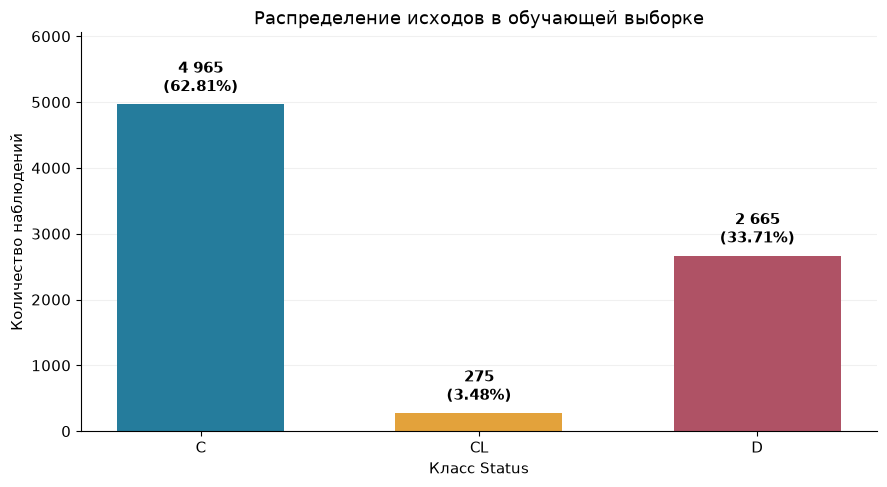

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(CLASSES, counts.values, color=['#257C9C', '#E3A23B', '#AF5265'], width=0.6)
for bar, count, share in zip(bars, counts.values, shares.values):
    label = f'{count:,}'.replace(',', ' ') + f'\n({share:.2%})'
    ax.text(bar.get_x() + bar.get_width()/2, count + counts.max()*0.025,
            label, ha='center', va='bottom', fontweight='bold')
ax.set(title='Распределение исходов в обучающей выборке',
       xlabel='Класс Status', ylabel='Количество наблюдений', ylim=(0, counts.max()*1.22))
ax.spines[['top', 'right']].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.18)
fig.tight_layout()
plt.show()

### 6.3 Оценка дисбаланса
Отношение численности самого частого класса к самому редкому: **IR = n_max / n_min**. Дополнительно учитываем абсолютное число наблюдений редкого класса. Единого универсального порога «сильного дисбаланса» для всех задач нет.

Accuracy постоянного прогноза наиболее частого класса показывает, почему общей доли правильных ответов недостаточно. Это описательный ориентир на всей выборке, а не проверенная на отложенных данных модель.

In [28]:
majority = counts.idxmax()
minority = counts.idxmin()
imbalance_ratio = counts.max() / counts.min()
print(f'Самый частый класс: {majority} — {counts.max()} ({shares[majority]:.2%}).')
print(f'Самый редкий класс: {minority} — {counts.min()} ({shares[minority]:.2%}).')
print(f'Отношение {majority}/{minority}: {imbalance_ratio:.2f}:1.')
print(f'Отношение D/CL: {counts["D"] / counts["CL"]:.2f}:1.')
print(f'Accuracy постоянного прогноза {majority}: {shares[majority]:.2%}.')

Самый частый класс: C — 4965 (62.81%).
Самый редкий класс: CL — 275 (3.48%).
Отношение C/CL: 18.05:1.
Отношение D/CL: 9.69:1.
Accuracy постоянного прогноза C: 62.81%.


### 6.4 Демонстрация стратифицированного разбиения 80/20
Фиксируем random_state. Стратификация сохраняет близкие доли классов, но не устраняет дисбаланс. Отложенная часть выделяется из train.csv, конкурсный test.csv не используется для локальной оценки качества.

In [29]:

train_idx, valid_idx = train_test_split(
    train.index, test_size=0.20, random_state=RANDOM_STATE, stratify=target
)
train_counts = target.loc[train_idx].value_counts().reindex(CLASSES, fill_value=0)
valid_counts = target.loc[valid_idx].value_counts().reindex(CLASSES, fill_value=0)
split_summary = pd.DataFrame({
    'Всего': counts,
    'Обучение, n': train_counts,
    'Обучение, %': train_counts / len(train_idx) * 100,
    'Валидация, n': valid_counts,
    'Валидация, %': valid_counts / len(valid_idx) * 100,
})
print(split_summary.to_string())
print(f'Обучение: {len(train_idx)}; валидация: {len(valid_idx)}.')


        Всего  Обучение, n  Обучение, %  Валидация, n  Валидация, %
Status                                                             
C        4965         3972        62.81           993         62.81
CL        275          220         3.48            55          3.48
D        2665         2132        33.71           533         33.71
Обучение: 6324; валидация: 1581.


### 6.5 Представленность классов при пятифолдовой кросс-валидации
Демонстрация на всей исходной обучающей выборке.

In [30]:


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_counts = []
for fold, (_, fold_valid_idx) in enumerate(cv.split(train, target), start=1):
    current = target.iloc[fold_valid_idx].value_counts().reindex(CLASSES, fill_value=0)
    fold_counts.append({'Фолд': fold, **current.to_dict()})
print(pd.DataFrame(fold_counts).set_index('Фолд').to_string())

        C  CL    D
Фолд              
1     993  55  533
2     993  55  533
3     993  55  533
4     993  55  533
5     993  55  533


### 6.6 Вывод по рассчитанным данным

In [31]:
print(f'В обучающей выборке {len(train)} наблюдений. '
      f'Класс C: {counts["C"]} ({shares["C"]:.2%}); '
      f'CL: {counts["CL"]} ({shares["CL"]:.2%}); '
      f'D: {counts["D"]} ({shares["D"]:.2%}).')
print(f'Распределение неравномерно: класс {majority} встречается '
      f'в {imbalance_ratio:.2f} раза чаще класса {minority}. '
      'Дисбаланс следует учитывать при разбиении и оценке моделей.')

В обучающей выборке 7905 наблюдений. Класс C: 4965 (62.81%); CL: 275 (3.48%); D: 2665 (33.71%).
Распределение неравномерно: класс C встречается в 18.05 раза чаще класса CL. Дисбаланс следует учитывать при разбиении и оценке моделей.


Выводы

Стратификация точно сохраняет исходные пропорции классов как в обучающей, так и в валидационной выборке. Однако при однократном разбиении 80/20 в валидацию попадает всего 55 наблюдений редкого класса CL, из-за чего случайная ошибка на нескольких пациентах сильно исказит метрики. Поэтому для надёжной локальной оценки моделей далее будем использовать стратифицированную 5-фолдовую кросс-валидацию (StratifiedKFold)





## 7. Распределение целевого признака по Категориальным признакам

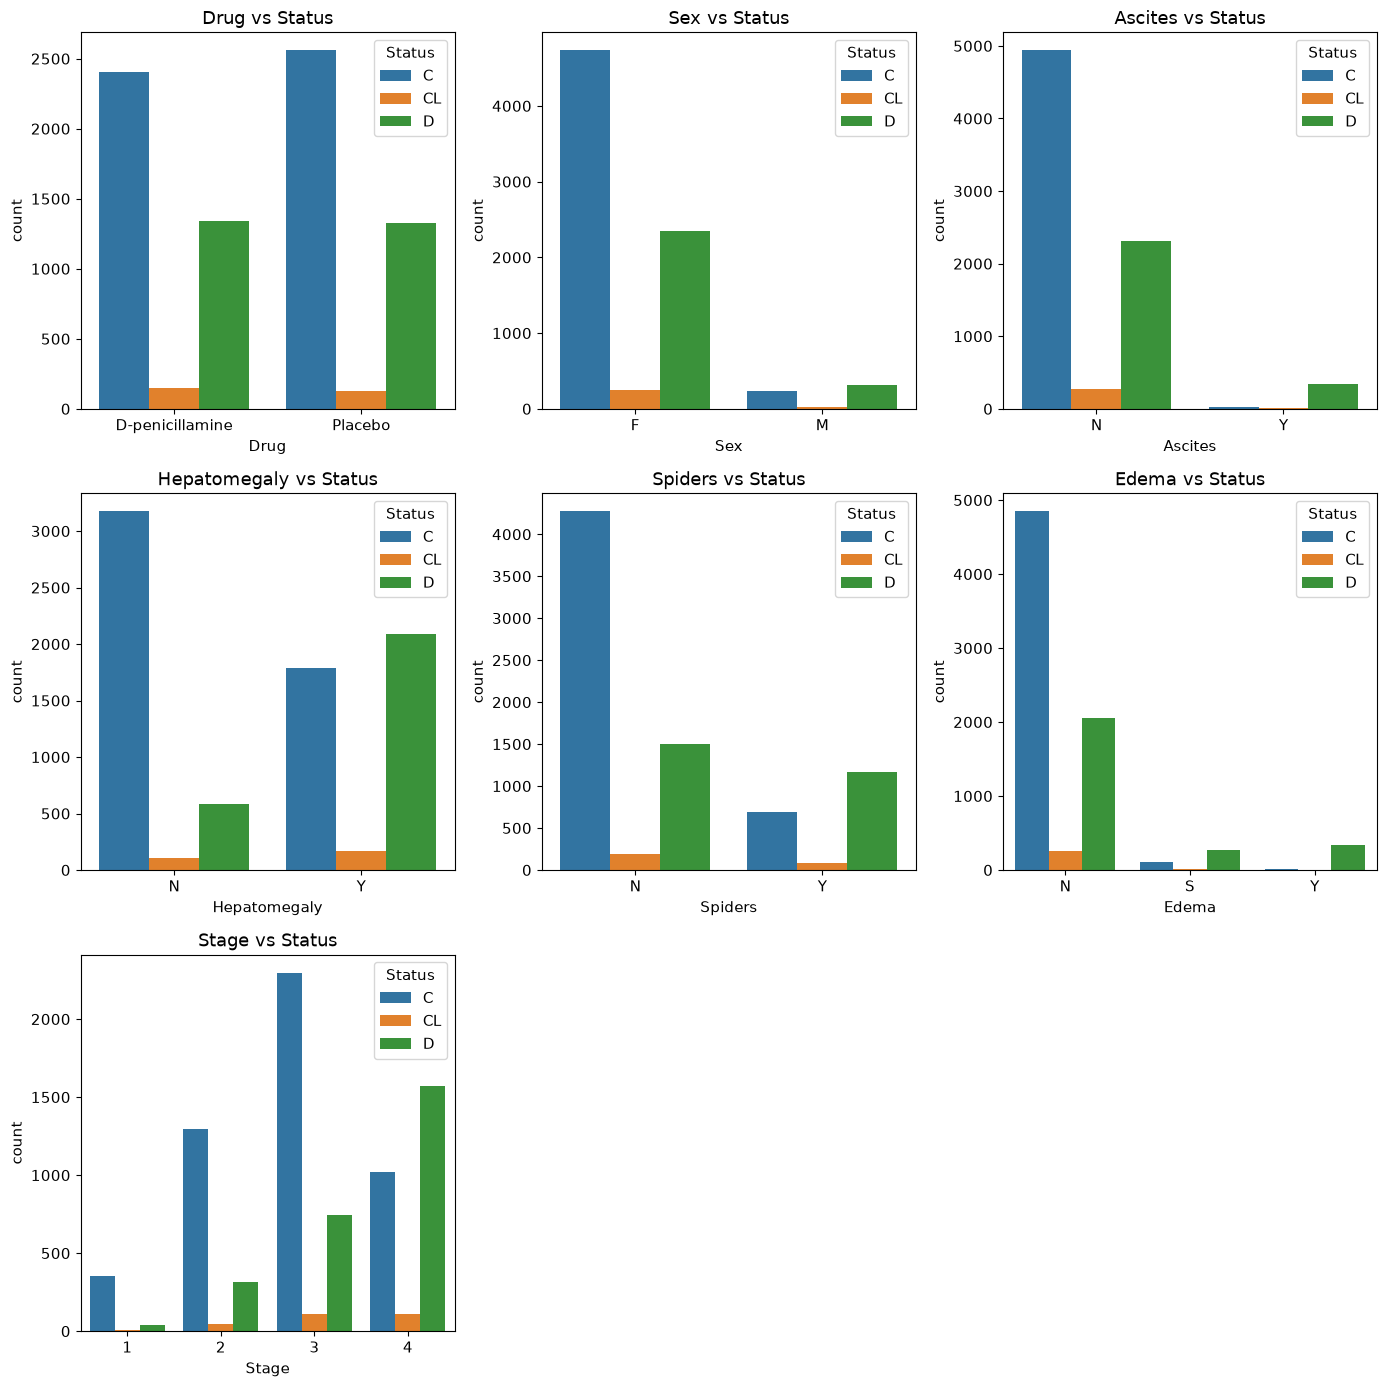

In [32]:
LABEL = 'Status'

plt.figure(figsize=(14, len(CAT_FEATS) * 2))
for i, col in enumerate(CAT_FEATS):
    plt.subplot(int(np.ceil(len(CAT_FEATS) / 3)), 3, i + 1)
    sns.countplot(x=col, hue=LABEL, data=train_clear)
    plt.title(f"{col} vs {LABEL}")
    plt.tight_layout()
plt.show()

In [33]:
bilirubin_by_sex = train_clear.groupby("Sex", observed=False)["Bilirubin"].agg(
    Пациентов="count",
    Медиана="median",
    Среднее="mean",
    Q25=lambda s: s.quantile(0.25),
    Q75=lambda s: s.quantile(0.75)
)
bilirubin_by_sex

,Пациентов,Медиана,Среднее,Q25,Q75
Sex,,,,,
F,7336,1.10,2.56,0.70,2.80
M,569,2.10,3.10,1.00,4.00


* В этой выборке медиана `Bilirubin` у мужчин выше, чем у женщин (2,1 против 1,1). Причины различия по данным EDA установить нельзя; качество модели для мужчин стоит оценивать отдельно.
* Распределения `Drug` по группам близки. Наличие или отсутствие эффекта лечения из этих графиков не следует

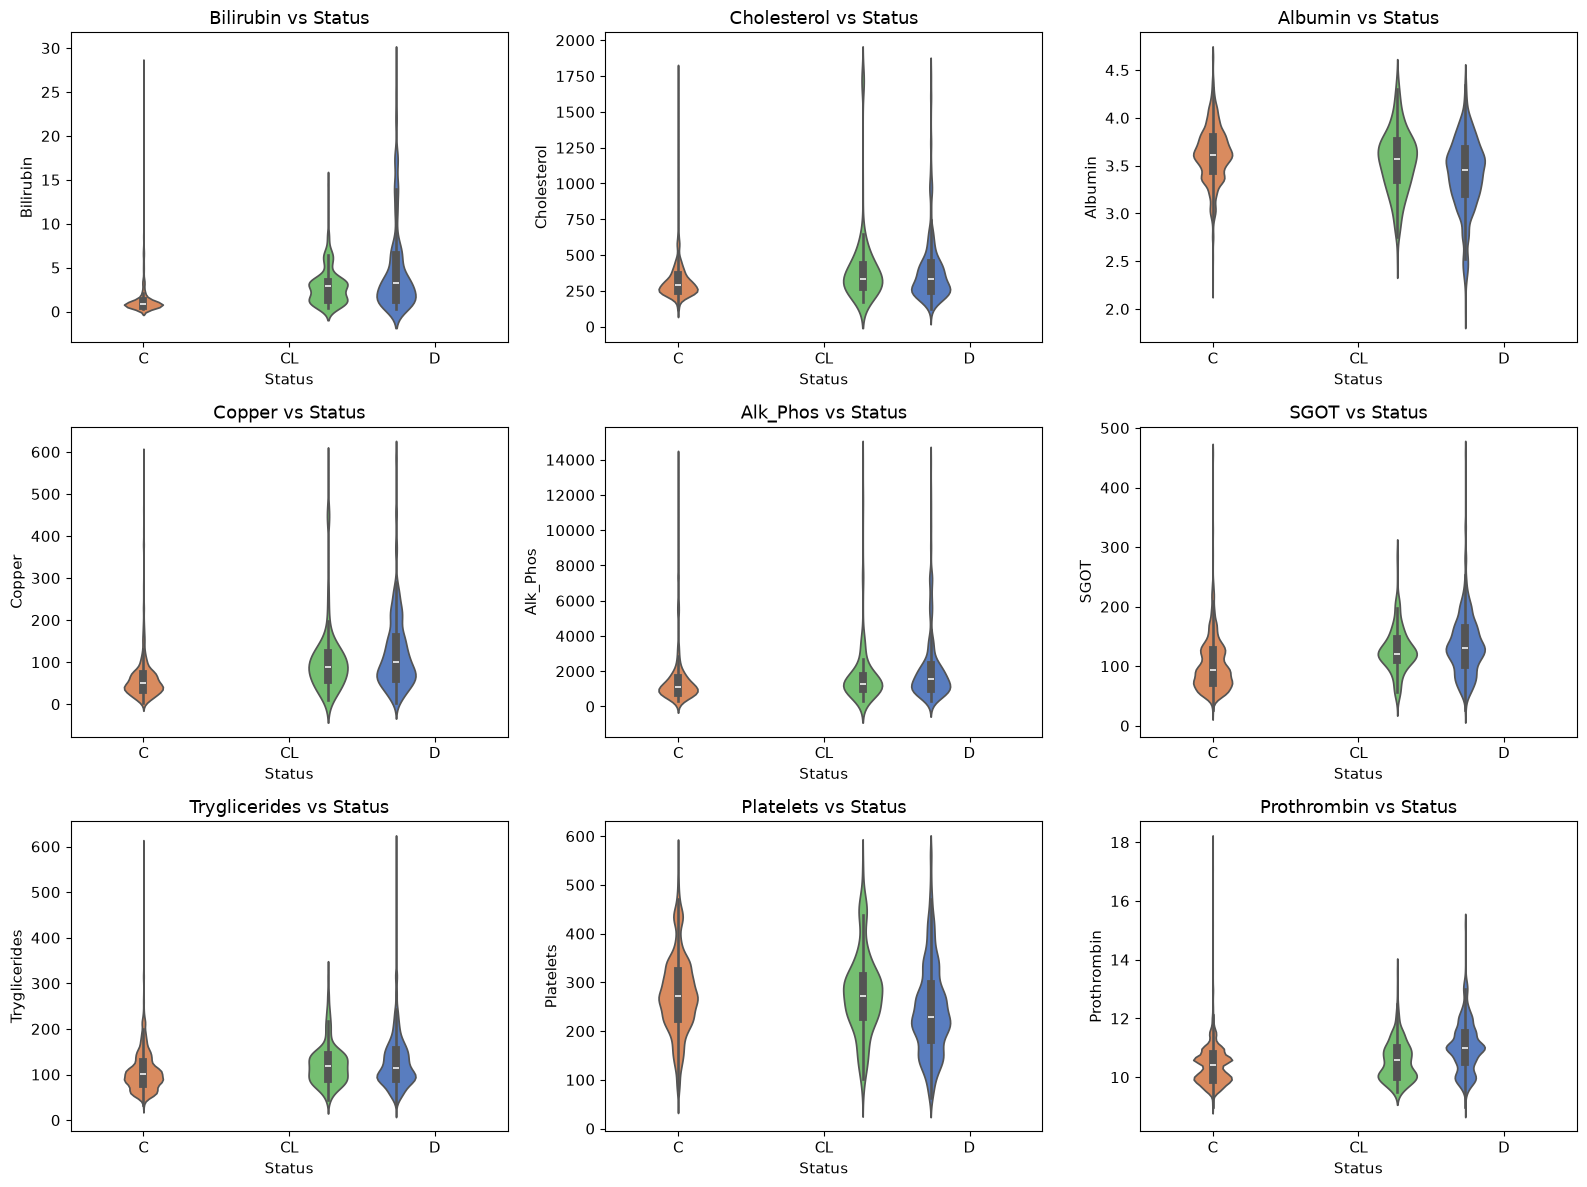

In [34]:
n = len(clean_num_feats)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))

axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, clean_num_feats):
    sns.violinplot(x="Status", y=col, data=train_clear,
                   ax=ax, hue="Status", palette="muted", legend=False)
    ax.set_title(f"{col} vs Status")

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [35]:
# Проверяем численность группы, прежде чем делать вывод по проценту.
edema_ascites_group = train_clear[
    (train_clear["Edema"] == "Y") & (train_clear["Ascites"] == "Y")
]
d_count = (edema_ascites_group["Status"] == "D").sum()
print(f"Edema=Y и Ascites=Y: {len(edema_ascites_group)} пациентов")
print(f"Статус D: {d_count} из {len(edema_ascites_group)} "
      f"({d_count / len(edema_ascites_group):.1%})")

Edema=Y и Ascites=Y: 244 пациентов
Статус D: 240 из 244 (98.4%)



* Сдвиг в распределении Bilirubin между мужчинами и женщинами не формирует самостоятельного разделения классов и связан с базовыми физиологическими нормами, поэтому признак Sex сохраняется в базовом наборе без создания специальных взаимодействий с ним
* Распределение целевой переменной практически не меняется в зависимости от группы лечения (D-penicillamine против Placebo), что указывает на слабую предсказательную силу признака.
* В группе `Edema=Y` и `Ascites=Y` статус `D` указан у 240 из 244 пациентов (98,4%). Что позволяет нам расматривать его как новый признак для однозначного определения класса

## 8. Корреляционный анализ

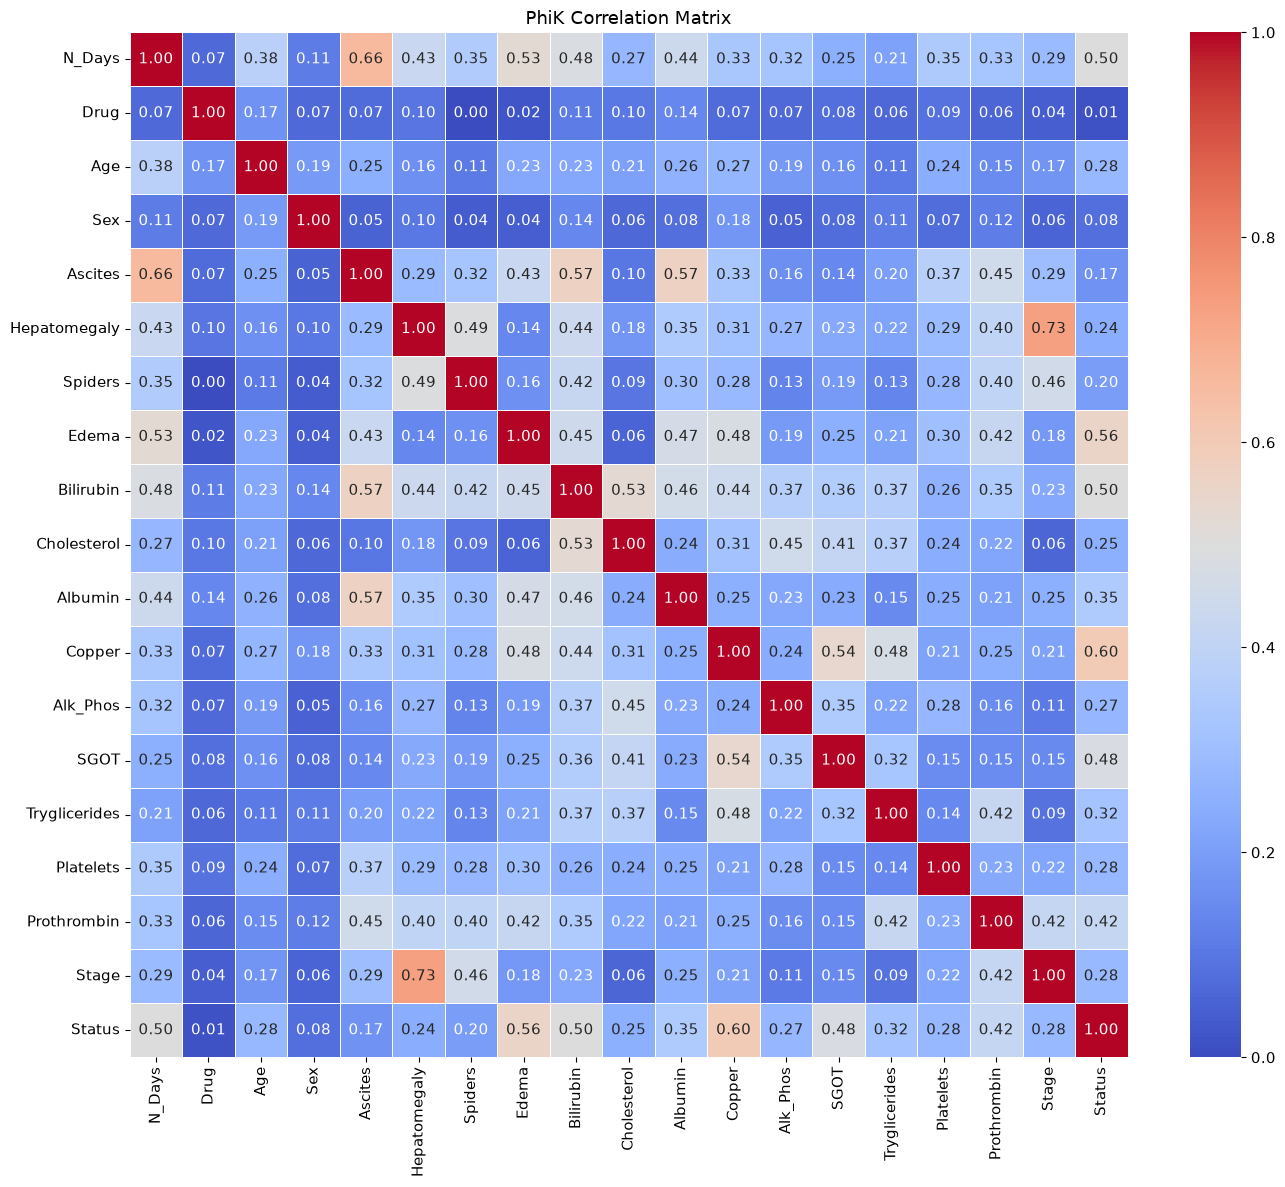

In [36]:
cols_for_corr = [column for column in train_clear.columns if column != "id"]
interval_cols = [
    column for column in train_clear.select_dtypes(include="number").columns
    if column != "Stage"
]
phik_matrix = phik.phik_matrix(train_clear[cols_for_corr], interval_cols=interval_cols)

plt.figure(figsize=(14, 12))
sns.heatmap(phik_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=0, vmax=1, linewidths=0.5)
plt.title("PhiK Correlation Matrix")
plt.tight_layout()
plt.show()

* **Гипотеза для моделирования:** связь `Drug` с `Status` по PhiK составляет около 0,01. Низкий PhiK сам по себе не доказывает бесполезность признака, однако является дополнительным аргументом в пользу проверки его удаления
* Выявлена сильная связь между `Stage` и `Hepatomegaly` (0,73), а также между `Ascites` и биохимическими показателями (`Albumin` — 0,57, `Bilirubin` — 0,57). Для линейных моделей это повышает риск неустойчивости весов и требует обязательного применения регуляризации
* Cтратегия кодирования категорий: для линейных моделей все категориальные признаки (Sex, Drug, Ascites, Spiders, Hepatomegaly, Edema, Stage) кодируются через OneHotEncoder для исключения строгой линейной зависимости


## 9. Гипотезы и инсайты для этапа машинного обучения

### 9.1 Анализ целевой переменной и качества данных
Выявлен выраженный дисбаланс классов: C встречается в 18,05 раза чаще CL (62,81% против 3,48%). Для сохранения пропорций классов при обучении следует использовать стратифицированную кросс-валидацию (StratifiedKFold, 5 фолдов). Также стоит проверить взвешивание классов (class_weight='balanced' или аналогичный механизм в выбранной модели).

Полных дубликатов в данных не обнаружено, поэтому удаление строк не требуется. Базовая Accuracy при прогнозе только наиболее частого класса составляет 62,81%, однако эта метрика не отражает качество распознавания редких классов. Для оценки моделей следует использовать multiclass log loss.

Отдельно стоит учитывать демографический перекос выборки: мужчины составляют всего 7,2% пациентов. На этапе валидации необходимо дополнительно проверить качество прогноза на мужской подгруппе, чтобы убедиться в отсутствии деградации модели на меньшинстве.

### 9.2 Анализ распределений и выбросов
Bilirubin, Cholesterol, Alk_Phos, Copper и Triglycerides имеют выраженную правую асимметрию. Экстремальные значения отражают тяжесть заболевания у пациентов, поэтому удалять их автоматически не следует. Для линейных моделей стоит сравнить стандартное масштабирование (StandardScaler) с устойчивым к выбросам RobustScaler (на основе медианы и межквартильного размаха), а также с логарифмированием np.log1p. Для моделей на основе деревьев решений масштабирование не требуется.

Albumin имеет левую асимметрию. В подгруппе пациентов со значениями ниже нижней границы IQR существенно преобладают летальные исходы (Status = D), что указывает на высокую информативность низких значений альбумина для прогноза.

### 9.3 Категориальные признаки и кодирование
Категории Drug распределены практически поровну (50,7% и 49,3%), но равенство частот не показывает связь с целевой переменной. Полезность признака целесообразно проверить для вероятного исключения.

Stage и Edema имеют упорядоченные категории, отражающие нарастание тяжести состояния. При обычном One-Hot Encoding информация о порядке уровней теряется, поэтому на валидации стоит сравнить One-Hot с порядковым кодированием (Ordinal Encoding: например, N=0, S=1, Y=2 для Edema и числовые значения 1–4 для Stage).

### 9.4 Генерация признаков
В группе Edema == 'Y' и Ascites == 'Y' статус D указан у 240 из 244 пациентов (98,4%). Это гипотеза для проверки бинарного признака edema_ascites_combination на валидации; по одной подгруппе качество модели неизвестно.

Гипотеза: Stage и Bilirubin могут дополнять друг друга при прогнозировании исхода. Проверим, улучшает ли признак Bilirubin * Stage качество на валидации; их сравнительная важность пока не установлена.

Дополнительно стоит проверить общий индекс клинических осложнений (суммарное количество присутствующих симптомов: Ascites, Hepatomegaly, Spiders и балл за Edema), так как накопление сразу нескольких признаков указывает на переход заболевания в стадию декомпенсации.

### 9.5 Интегральные медицинские шкалы
Альбумин, билирубин и протромбиновое время отражают разные аспекты функции печени. В качестве дополнительных признаков можно рассмотреть клиническиерасчетные показатели. Для их расчёта необходимо проверить единицы измерения и наличие всех необходимых переменных.

### 9.6 Методологические ограничения
N_Days связан с определением целевой переменной Status. Для конкурсной задачи Kaggle его использование допустимо в рамках заданной постановки. Однако для клинического прогноза на момент первичного обращения этот признак необходимо исключить, поскольку он содержит информацию о будущем периоде наблюдения и создаёт риск утечки данных (data leakage).

## 10. Протокол валидации и вспомогательные функции

В этом разделе один раз подготавливаем данные и фиксируем правила оценки, общие для всех последующих моделей.

Используем train_clear, созданный в EDA: в нём уже удалён технический столбец id. Целевой признак Status отделяем от матрицы признаков. Для всех моделей заранее фиксируем одни и те же пять стратифицированных фолдов (cv_splits).

Основная метрика — **Multiclass Log Loss**: она оценивает качество предсказанных вероятностей трёх классов. Дополнительно сохраняем Accuracy и Macro F1. Также рассчитываем наивную точку отсчёта: модель предсказывает априорные вероятности классов, рассчитанные только на обучающей части каждого фолда.

Функция evaluate_cv() будет использоваться для оценки всех следующих моделей. Это позволит сравнивать их на одинаковых разбиениях и не дублировать цикл кросс-валидации.

In [37]:
X = train_clear.drop(columns=["Status"]).copy()
y = train_clear["Status"].copy()

# Материализуем разбиения один раз и далее используем их для всех моделей.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X, y))
cv_results = pd.DataFrame()


In [38]:
folds_summary = []

for fold, (train_id, valid_id) in enumerate(cv_splits, start=1):
    train_counts = y.iloc[train_id].value_counts().reindex(CLASSES)
    valid_counts = y.iloc[valid_id].value_counts().reindex(CLASSES)

    folds_summary.append({
        "Fold": fold,
        "Train size": len(train_idx),
        "Valid size": len(valid_idx),
        **{f"Train_{c}": train_counts[c] for c in CLASSES},
        **{f"Valid_{c}": valid_counts[c] for c in CLASSES}
    })

folds_summary_df = pd.DataFrame(folds_summary).set_index("Fold")

display(folds_summary_df)

,Train size,Valid size,Train_C,Train_CL,Train_D,Valid_C,Valid_CL,Valid_D
Fold,,,,,,,,
1,6324,1581,3972,220,2132,993,55,533
2,6324,1581,3972,220,2132,993,55,533
3,6324,1581,3972,220,2132,993,55,533
4,6324,1581,3972,220,2132,993,55,533
5,6324,1581,3972,220,2132,993,55,533


cv_splits содержит конкретные индексы пяти фолдов. Все модели будут оцениваться на одних и тех же обучающих и валидационных частях.
cv_results - общий список результатов. В него попадут метрики наивной модели и всех последующих алгоритмов.
Разбиение стратифицированное: доли классов в каждом фолде близки к долям в исходной выборке.

### 10.1 Единая функция оценки моделей

Функция evaluate_cv() принимает подготовленный конвейер или модель, обучает его отдельно на каждом обучающем фолде, рассчитывает метрики на соответствующей валидационной части, также создаем функции add_result() для добавления результатов в общий логгер и show_logger() для вывода таблица с метриками.

Порядок классов для Log Loss фиксируем через CLASSES. Перед расчётом вероятности при необходимости переставляются в этот порядок: это защищает от ошибки, если модель возвращает столбцы вероятностей в другом порядке.

In [39]:
def evaluate_cv(
    pipeline: Pipeline,
    model_name: str,
    data_x: pd.DataFrame=X,
    data_y: pd.Series=y,
    splits: list=cv_splits,
    classes: list[str]=CLASSES
) -> pd.DataFrame:

    """
    Оценивает модель с использованием фиксированных фолдов кросс-валидации.

    Args:
        pipeline (Pipeline): Пайплайн предобработки данных и обучения модели.
        model_name (str): Название модели.
        X (pd.DataFrame): Таблица признаков.
        y (pd.Series): Целевая переменная.
        splits (list): Список фолдов с индексами обучающих и валидационных объектов.
        classes (list[str]): Упорядоченный список классов целевой переменной.

    Return: pd.DataFrame, таблица с метриками качества и временем обучения и предсказания для каждого фолда.
    """

    fold_results = []

    for fold, (train_idx, valid_idx) in enumerate(splits, start=1):

        X_train = data_x.iloc[train_idx]
        X_valid = data_x.iloc[valid_idx]

        y_train = data_y.iloc[train_idx]
        y_valid = data_y.iloc[valid_idx]

        model = clone(pipeline)

        start_time = time.perf_counter()
        model.fit(X_train, y_train)
        fit_time = time.perf_counter() - start_time

        start_time = time.perf_counter()
        predictions = model.predict(X_valid)
        probabilities = model.predict_proba(X_valid)
        predict_time = time.perf_counter() - start_time

        class_indices = [list(model.classes_).index(c) for c in classes]
        probabilities = probabilities[:, class_indices]

        recalls = recall_score(
            y_valid,
            predictions,
            labels=classes,
            average=None,
            zero_division=0
        )

        fold_results.append({
            "Model": model_name,
            "Fold": fold,
            "Log Loss": log_loss(y_valid, probabilities, labels=classes),
            "Accuracy": accuracy_score(y_valid, predictions),
            "Macro F1": f1_score(
                y_valid, predictions,
                labels=classes,
                average="macro",
                zero_division=0
            ),
            "Recall_C": recalls[0],
            "Recall_CL": recalls[1],
            "Recall_D": recalls[2],
            "Fit Time (s)": fit_time,
            "Predict Time (s)": predict_time
        })

    return pd.DataFrame(fold_results)


def add_result (results_model: pd.DataFrame, logger: pd.DataFrame) -> pd.DataFrame:

    """
    Добавляет результаты модели в общий логгер.
    """

    logger = pd.concat(
        [
            logger,
            results_model,
        ],
        ignore_index=True
    )
    return logger

def show_logger(
    df: pd.DataFrame | None = None,
    detail_metrics: tuple[str, ...] = ("Log Loss",),
    detail_aggs: tuple[str, ...] = ("mean", "median", "std"),
    base_aggs: tuple[str, ...] = ("mean",),
    sort_by: str = "Log Loss (mean)",
) -> None:
    """
    Выводит сводную таблицу результатов моделей:
    расширенные статистики для detail_metrics, среднее для остальных
    и сортировку по возрастанию sort_by.
    """
    if df is None:
        df = cv_results

    metrics = [col for col in df.columns if col not in ("Model", "Fold")]

    agg_dict = {
        col: list(detail_aggs) if col in detail_metrics else list(base_aggs)
        for col in metrics
    }

    summary = df.groupby("Model").agg(agg_dict)
    summary.columns = [f"{col} ({stat})" for col, stat in summary.columns]
    summary = summary.reset_index()

    if sort_by in summary.columns:
        summary = summary.sort_values(by=sort_by, ascending=True)

    display(summary.round(5))

Для каждой модели используется одна и та же функция и одни и те же фолды. clone() гарантирует, что обучение на одном фолде не переносится на следующий. Результаты сохраняются в виде таблицы: для каждого фолда фиксируются Log Loss, Accuracy, Macro F1, Recall по каждому классу, время обучения и время предсказания.

Для сравнения моделей используются средние значения и стандартные отклонения метрик по фолдам. Log Loss минимизируется, Accuracy и Macro F1 максимизируются. Recall по каждому классу используется для дополнительного анализа качества классификации, особенно для редкого класса CL.

### 10.2 Наивная точка отсчёта: априорные вероятности классов

Сначала оценим простейшую модель без использования признаков. На каждом фолде она рассчитывает частоты классов только по обучающей части и возвращает эти частоты как вероятности для любого объекта валидации.

Для этого используем DummyClassifier(strategy="prior"). Такая оценка показывает, насколько хорошо можно справиться с задачей, просто зная распределение целевой переменной. Следующие модели должны превзойти эту точку отсчёта прежде, чем мы будем считать их полезными.

In [40]:
dummy_baseline = DummyClassifier(strategy="prior")

dummy_results = evaluate_cv(dummy_baseline, "Naive baseline (class frequencies)")

cv_results = add_result(dummy_results, cv_results)
show_logger()


,Model,Log Loss (mean),Log Loss (median),Log Loss (std),Accuracy (mean),Macro F1 (mean),Recall_C (mean),Recall_CL (mean),Recall_D (mean),Fit Time (s) (mean),Predict Time (s) (mean)
0,Naive baseline (class frequencies),0.78,0.78,0.00,0.63,0.26,1.00,0.00,0.00,0.00,0.00


Наивная модель не анализирует признаки пациента: она выдаёт одинаковое для всех объектов распределение вероятностей, рассчитанное по обучающей части текущего фолда. Если следующая модель не улучшает Log Loss относительно наивной, значит, пока она не научилась извлекать из признаков полезную информацию о вероятностях классов.

### 10.3 Универсальный препроцессинг для линейных моделей

Создаём универсальную функцию make_linear_preprocessor(), которая формирует конвейер предобработки признаков для всех линейных моделей и других алгоритмов, чувствительных к масштабу признаков.

Все категориальные признаки, кроме Edema, кодируем через OneHotEncoder(drop="first", handle_unknown="ignore"), включая Stage, который представлен числами, но по смыслу является категорией:
1) бинарные признаки (Sex, Drug, Ascites, Hepatomegaly, Spiders) автоматически преобразуются в один столбец 0/1;
2) многоклассовый признак Stage — в \(K - 1\) бинарных индикаторов относительно базовой категории, что позволяет линейной модели оценить индивидуальный вклад каждой стадии без допущения о равном шаге риска между ними.

Удаление первой категории (drop="first") избавляет линейную модель от строгой мультиколлинеарности и делает коэффициенты интерпретируемыми.

Порядковый признак Edema кодируется с сохранением клинической прогрессии тяжести (N < S < Y) через OrdinalEncoder и стандартизируется: редкие категории S (5,0%) и Y (4,4%) малочисленны, поэтому единая числовая шкала позволяет устойчиво оценивать нарастание тяжести отёков без переобучения на малых подгруппах.

Числовые и закодированные порядковые признаки приводятся к единому масштабу. Аргумент scaler позволяет гибко переключать способ масштабирования в будущих экспериментах, выбирая между стандартизацией (StandardScaler), нормализацией в диапазон  (MinMaxScaler) или устойчивым к выбросам масштабированием (RobustScaler). Функция возвращает необученный объект ColumnTransformer, который при передаче в evaluate_cv() клонируется и обучается строго на тренировочной части каждого фолда, гарантируя отсутствие утечки данных.


In [41]:
def make_linear_preprocessor(
        df: pd.DataFrame = X,
        scaler: StandardScaler = StandardScaler()
    ) -> ColumnTransformer:

    """Создаёт препроцессор для подготовки признаков к обучению линейных моделей."""

    ord_cols = ["Edema"]
    ohe_extra = ["Stage"]
    num_cols = [c for c in df.select_dtypes(include="number").columns if c not in ohe_extra]
    cat_cols = [c for c in df.select_dtypes(include="category").columns if c not in ord_cols] + ohe_extra

    num_scaler = clone(scaler) if scaler != "passthrough" else "passthrough"
    ord_scaler = clone(scaler) if scaler != "passthrough" else "passthrough"

    return ColumnTransformer([
        ("ord", Pipeline([
            ("enc", OrdinalEncoder(categories=[["N", "S", "Y"]])),
            ("scaler", ord_scaler),
        ]), ord_cols),
        ("num", num_scaler, num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
    ])

## 11. Базовая модель: Logistic Regression

Теперь обучим первую базовую модель — многоклассовую логистическую регрессию на исходном наборе признаков (без генерации новых фич и нелинейных преобразований). Она станет отправной точкой для дальнейших экспериментов.

Числовые признаки стандартизируем с помощью StandardScaler.
Препроцессор и модель LogisticRegression объединены в единый конвейер Pipeline. При передаче в evaluate_cv() конвейер клонируется и обучается заново на тренировочной части каждого из пяти стратифицированных фолдов, что полностью исключает утечку данных.

Оценку проводим через общую функцию evaluate_cv(). Дополнительно собираем out-of-fold предсказания, чтобы построить матрицу ошибок и проверить качество модели на редком классе CL и мужской подгруппе.





In [42]:
logreg_pipeline = Pipeline(
    steps=[
        ("preprocessor", make_linear_preprocessor(df=X, scaler=StandardScaler())),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]
)

logreg_results = evaluate_cv(logreg_pipeline, "Logistic Regression (Baseline)")

cv_results = add_result(logreg_results, cv_results)
show_logger()


,Model,Log Loss (mean),Log Loss (median),Log Loss (std),Accuracy (mean),Macro F1 (mean),Recall_C (mean),Recall_CL (mean),Recall_D (mean),Fit Time (s) (mean),Predict Time (s) (mean)
0,Logistic Regression (Baseline),0.53,0.53,0.01,0.80,0.52,0.91,0.00,0.67,0.05,0.01
1,Naive baseline (class frequencies),0.78,0.78,0.00,0.63,0.26,1.00,0.00,0.00,0.00,0.00


In [43]:
# Диагностика качества по классам и подгруппам на out-of-fold предсказаниях
oof_preds = pd.Series(index=X.index, dtype="object")
oof_probs = np.zeros((len(X), len(CLASSES)))

for train_idx, valid_idx in cv_splits:
    model_fold = clone(logreg_pipeline)
    model_fold.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_preds.iloc[valid_idx] = model_fold.predict(X.iloc[valid_idx])

    probs_fold = model_fold.predict_proba(X.iloc[valid_idx])
    order = [list(model_fold.classes_).index(c) for c in CLASSES]
    oof_probs[valid_idx] = probs_fold[:, order]

print("Отчёт по классам (OOF):")
print(classification_report(y, oof_preds, labels=CLASSES, digits=3, zero_division=0))

Отчёт по классам (OOF):
              precision    recall  f1-score   support

           C      0.811     0.907     0.856      4965
          CL      0.000     0.000     0.000       275
           D      0.759     0.669     0.711      2665

    accuracy                          0.795      7905
   macro avg      0.523     0.525     0.522      7905
weighted avg      0.765     0.795     0.777      7905



Log Loss (все пациенты): 0.52719
Log Loss (мужчины, n=569): 0.77117


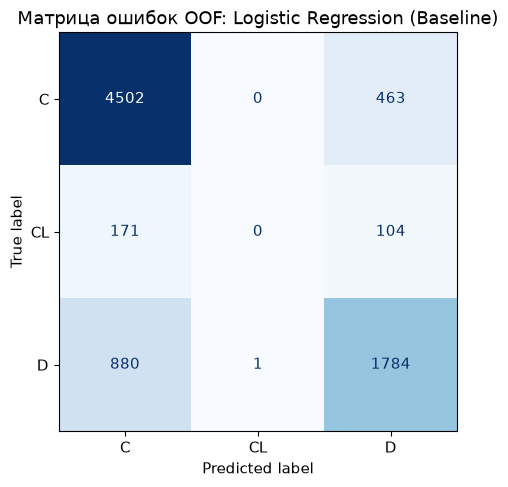

In [44]:
male_mask = X["Sex"] == "M"
print(f"Log Loss (все пациенты): {log_loss(y, oof_probs, labels=CLASSES):.5f}")
print(f"Log Loss (мужчины, n={male_mask.sum()}): {log_loss(y[male_mask], oof_probs[male_mask], labels=CLASSES):.5f}")

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y, oof_preds, labels=CLASSES)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Матрица ошибок OOF: Logistic Regression (Baseline)")
plt.tight_layout()
plt.show()

Логистическая регрессия уверенно превосходит наивный базовый прогноз: средний Log Loss снизился с ~0.778 до ~0.52, выросли Accuracy и Macro F1. Это свидетельствует о том, что признаки содержат выраженный сигнал для предсказания исходов. Модель хорошо распознаёт частые классы C и D, однако не смогла правильно классифицировать ни одного объекта редкого класса CL, что отражается в нулевом Recall для этого класса. Вероятной причиной является сильный дисбаланс классов: доля CL составляет всего 3,48% выборки. Таким образом, несмотря на улучшение общих метрик относительно наивного прогноза, модель пока не обеспечивает качественного распознавания всех трёх классов.


## 12. Разработка и отбор новых признаков

На основе разведочного анализа данных и клинической предметной области формируем набор новых признаков, отражающих степень печёночной недостаточности, выраженность осложнений и биохимические соотношения.

Все преобразования оформим в виде воспроизводимой функции, пригодной для встраивания в `sklearn.pipeline.Pipeline`, и оценим вклад каждого признака.


### 12.1 Клиническое и математическое обоснование признаков



Индекс риска Мейо (Mayo_score_cont и флаг Mayo_high_risk_flg):
   "Золотой стандарт" оценки прогноза при первичном билиарном циррозе (Mayo PBC Risk Score). Объединяет возраст, билирубин, альбумин, протромбиновое время и выраженность отёков:
   $$R = 0.039 \cdot \text{Age}_{\text{years}} + 0.871 \cdot \ln(\text{Bilirubin}) + 0.859 \cdot \text{Edema}_{\text{num}} - 2.53 \cdot \ln(\text{Albumin}) + 2.38 \cdot \ln(\text{Prothrombin})$$
   * Единицы измерения: возраст переводится из дней в годы (Age / 365), отёки кодируются как N = 0.0, S = 0.5, Y = 1.0, остальные показатели в датасете уже представлены в нужных единицах (мг/дл, г/дл, сек).
   * Клинический порог: значение $R \ge 7.8$ соответствует высокому риску летального исхода и показанию к трансплантации печени. На валидации сравним непрерывный индекс и бинарный порог.

 Шкала ALBI (Albi_score_cont и степень Albi_grade):
   Шкала Albumin-Bilirubin для объективной оценки синтетической и экскреторной функции печени:
   $$\text{ALBI} = 0.66 \cdot \log_{10}(\text{Bilirubin}_{\text{мкмоль/л}}) - 0.085 \cdot \text{Albumin}_{\text{г/л}}$$
   * Перевод единиц: $\text{Bilirubin}_{\text{мкмоль/л}} = \text{Bilirubin}_{\text{мг/дл}} \times 17.1$; $\text{Albumin}_{\text{г/л}} = \text{Albumin}_{\text{г/дл}} \times 10$.
   * Градации: степень 1 ($\le -2.60$) — компенсация; степень 2 ($-2.60 \dots -1.39$) — умеренная декомпенсация; степень 3 ($> -1.39$) — выраженная декомпенсация.

Флаг экстремальной печёночной недостаточности (Is_liver_failure):
   Комбинация критических отклонений по правилам IQR (Bilirubin > 6.45, Albumin < 2.72) с клиническими признаками задержки жидкости (Ascites == 'Y' или Edema в ['S', 'Y']).

Индекс клинических осложнений (Complications_index):
   Суммарная тяжесть портальной гипертензии и печёночно-клеточной недостаточности: сумма бинарных флагов Ascites, Hepatomegaly, Spiders и числового балла Edema ($0 \dots 1$).

Биохимические отношения и взаимодействия (APRI_ratio, Bili_Alb_ratio, Stage_x_LogBili):
* APRI_ratio = SGOT / Platelets — клинический индекс фиброза и цирроза печени (отношение АСТ к тромбоцитам).
* Bili_Alb_ratio = Bilirubin / Albumin — прямое отношение холестаза к белково-синтетической функции.
* Stage_x_LogBili = Stage * log1p(Bilirubin) — взаимодействие гистологической стадии и выраженности желтухи.

Отбор признаков (drop_drug):
   Проверка гипотезы об исключении признака Drug (тип терапии), показавшего околонулевую связь с целевой переменной (PhiK = 0.01).

In [45]:
# Клинические константы и пороги
DAYS_IN_YEAR = 365
BILI_MG_TO_UMOL = 17.1
ALB_GDL_TO_GL = 10.0
MAYO_HIGH_RISK_THRESHOLD = 7.8
ALBI_BINS = [-np.inf, -2.60, -1.39, np.inf]
ALBI_LABELS = [1,2,3]
EDEMA_WEIGHT_MAP = {'N': 0.0, 'S': 0.5, 'Y': 1.0}

In [46]:
def create_medical_features(
    df: pd.DataFrame,
    use_liver_failure: bool = True,
    use_mayo_cont: bool = True,
    use_mayo_flag: bool = False,
    use_albi_cont: bool = True,
    use_albi_grade: bool = False,
    use_complications: bool = True,
    use_ratios: bool = True,
    drop_drug: bool = False,
) -> pd.DataFrame:
    """Генерирует клинические шкалы и биохимические признаки внутри пайплайна."""
    df_out = df.copy()
    edema_num = df_out['Edema'].map(EDEMA_WEIGHT_MAP).astype(float)

    # Флаг отказа печени
    if use_liver_failure:
        df_out['Is_liver_failure'] = (
            (df_out['Bilirubin'] > 6.45)
            & ((df_out['Ascites'] == 'Y') | (df_out['Edema'].isin(['Y', 'S'])))
            & (df_out['Albumin'] < 2.72)
        ).astype(int)

    #  Mayo PBC Score
    if use_mayo_cont or use_mayo_flag:
        age_years = (df_out['Age'] / DAYS_IN_YEAR).astype(int)
        mayo_val = (
            0.039 * age_years
            + 0.871 * np.log(df_out['Bilirubin'])
            + 0.859 * edema_num
            - 2.53 * np.log(df_out['Albumin'])
            + 2.38 * np.log(df_out['Prothrombin'])
        )
        if use_mayo_cont:
            df_out['Mayo_score_cont'] = mayo_val
        if use_mayo_flag:
            df_out['Mayo_high_risk_flg'] = (
                mayo_val >= MAYO_HIGH_RISK_THRESHOLD
            ).astype(int)

    # ALBI
    if use_albi_cont or use_albi_grade:
        bili_umol_l = df_out['Bilirubin'] * BILI_MG_TO_UMOL
        albumin_g_l = df_out['Albumin'] * ALB_GDL_TO_GL
        albi_val = np.log10(bili_umol_l) * 0.66 - 0.085 * albumin_g_l

        if use_albi_cont:
            df_out['Albi_score_cont'] = albi_val
        if use_albi_grade:
            df_out['Albi_grade'] = pd.cut(
                albi_val, bins=ALBI_BINS, labels=ALBI_LABELS
            ).astype(int)

    # Суммарный индекс клинических осложнений
    if use_complications:
        df_out['Complications_index'] = (
            (df_out['Ascites'] == 'Y').astype(int)
            + (df_out['Hepatomegaly'] == 'Y').astype(int)
            + (df_out['Spiders'] == 'Y').astype(int)
            + edema_num
        )

    # Биохимические отношения
    if use_ratios:
        df_out['APRI_ratio'] = df_out['SGOT'] / df_out['Platelets']
        df_out['Bili_Alb_ratio'] = df_out['Bilirubin'] / df_out['Albumin']
        df_out['Stage_x_LogBili'] = df_out['Stage'].astype(float) * np.log1p(
            df_out['Bilirubin']
        )

    # удаление Drug
    if drop_drug and 'Drug' in df_out.columns:
        df_out = df_out.drop(columns=['Drug'])

    return df_out


### 12.2 Изолированная проверка каждого признака

In [47]:
cv_fe = pd.DataFrame()
base_feat_params = {
    'use_liver_failure': False,
    'use_mayo_cont': False,
    'use_mayo_flag': False,
    'use_albi_cont': False,
    'use_albi_grade': False,
    'use_complications': False,
    'use_ratios': False,
    'drop_drug': False,
}

feature_experiments = {
    '+ Is_liver_failure': {'use_liver_failure': True},
    '+ Mayo_score (непрерывный)': {'use_mayo_cont': True},
    '+ Mayo_score (флаг >= 7.8)': {'use_mayo_flag': True},
    '+ Albi_score (непрерывный)': {'use_albi_cont': True},
    '+ Albi_grade (степень 1-3)': {'use_albi_grade': True},
    '+ Complications_index': {'use_complications': True},
    '+ Ratios (APRI, Bili/Alb, Stage*Bili)': {'use_ratios': True},
    '- Drop Drug': {'drop_drug': True},
}

for exp_name, exp_override in feature_experiments.items():
    params = {**base_feat_params, **exp_override}
    sample_df = create_medical_features(X.iloc[:5], **params)

    pipe = Pipeline(
        steps=[
            ('feat_gen', FunctionTransformer(create_medical_features, kw_args=params)),
            ('preprocessor', make_linear_preprocessor(
                    df=sample_df, scaler=StandardScaler())),
            ('classifier', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
        ]
    )

    feature_experiments_result = evaluate_cv(
        pipe, f'LogReg {exp_name}', X, y, cv_splits, CLASSES
    )

    cv_fe = add_result(feature_experiments_result, cv_fe)


show_logger(df=cv_fe)

,Model,Log Loss (mean),Log Loss (median),Log Loss (std),Accuracy (mean),Macro F1 (mean),Recall_C (mean),Recall_CL (mean),Recall_D (mean),Fit Time (s) (mean),Predict Time (s) (mean)
4,LogReg + Mayo_score (непрерывный),0.51,0.51,0.01,0.80,0.53,0.90,0.01,0.70,0.06,0.01
1,LogReg + Albi_score (непрерывный),0.51,0.51,0.01,0.80,0.53,0.90,0.01,0.70,0.06,0.01
6,"LogReg + Ratios (APRI, Bili/Alb, Stage*Bili)",0.52,0.52,0.02,0.80,0.53,0.91,0.01,0.68,0.05,0.01
5,LogReg + Mayo_score (флаг >= 7.8),0.53,0.53,0.01,0.79,0.52,0.91,0.00,0.67,0.06,0.01
3,LogReg + Is_liver_failure,0.53,0.53,0.01,0.80,0.52,0.91,0.00,0.67,0.05,0.01
0,LogReg + Albi_grade (степень 1-3),0.53,0.53,0.01,0.79,0.52,0.91,0.00,0.67,0.05,0.01
2,LogReg + Complications_index,0.53,0.53,0.01,0.80,0.52,0.91,0.00,0.67,0.05,0.01
7,LogReg - Drop Drug,0.53,0.53,0.01,0.79,0.52,0.91,0.00,0.67,0.05,0.01


### Выводы
Лидеры среди сгенерированных признаков (наибольшее снижение целевой метрики Multiclass Log Loss):
1. Непрерывный индекс риска Мейо (Mayo_score_cont)
2. Непрерывный балл шкалы ALBI (Albi_score_cont)

Непрерывные шкалы превосходят дискретизацию: Перевод медицинских индексов в пороговые флаги и степени практически не улучшает качество относительно непрерывных шкал.

Умеренный и околонулевой эффект: Индекс клинических осложнений (Complications_index) дал небольшой прирост, тогда как изолированный флаг отказа печени (Is_liver_failure) и удаление признака терапии (Drop Drug) существенного влияния на линейную регрессию не оказали.

### 12.3 Совместное тестирование способов масштабирования и логарифмирования



Проверим, как различные способы масштабирования (`StandardScaler`, `MinMaxScaler`, `RobustScaler`) и логарифмирование правосторонне скошенных признаков влияют на качество модели:
* на **исходных признаках**;
* на **обогащённом наборе признаков** (включающем непрерывные шкалы `Mayo_score_cont`, `Albi_score_cont`, `Complications_index`).


In [48]:
SELECTED_FEAT_PARAMS = {
    'use_liver_failure': False,
    'use_mayo_cont': True,
    'use_mayo_flag': False,
    'use_albi_cont': True,
    'use_albi_grade': False,
    'use_complications': True,
    'use_ratios': False,
    'drop_drug': False,
}


SKEWED_COLS = [
    'Bilirubin',
    'Cholesterol',
    'Alk_Phos',
    'Copper',
    'Tryglicerides',
    'SGOT',
]

In [49]:
def log_transform_skewed(df: pd.DataFrame) -> pd.DataFrame:
    """Логарифмирует сильно скошенные признаки через np.log1p."""
    df_out = df.copy()
    for col in SKEWED_COLS:
        if col in df_out.columns:
            df_out[col] = np.log1p(df_out[col])
    return df_out


In [50]:
sample_fe_df = create_medical_features(X, **SELECTED_FEAT_PARAMS)

cv_copmare_results = cv_results.copy()

scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
}

features = {
    "Base": ([], X),
    "Base + log1p": (
        [("log", FunctionTransformer(log_transform_skewed))],
        X
    ),
    "+features": (
        [("feat_gen", FunctionTransformer(
            create_medical_features, kw_args=SELECTED_FEAT_PARAMS
        ))],
        sample_fe_df
    ),
    "+features + log1p": (
        [
            ("feat_gen", FunctionTransformer(
                create_medical_features, kw_args=SELECTED_FEAT_PARAMS
            )),
            ("log", FunctionTransformer(log_transform_skewed))
        ],
        sample_fe_df
    )
}

for scaler_name, scaler_obj in scalers.items():
    for feature_name, (transformers, df) in features.items():

        pipeline = Pipeline(
            steps=[
                *transformers,
                ("preprocessor", make_linear_preprocessor(df=df, scaler=scaler_obj)),
                ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
            ]
        )

        model_name = f"LogReg [{feature_name}] + {scaler_name}"

        run_results = evaluate_cv(pipeline, model_name)
        cv_copmare_results = add_result(run_results, cv_copmare_results)


show_logger(df=cv_copmare_results)

,Model,Log Loss (mean),Log Loss (median),Log Loss (std),Accuracy (mean),Macro F1 (mean),Recall_C (mean),Recall_CL (mean),Recall_D (mean),Fit Time (s) (mean),Predict Time (s) (mean)
5,LogReg [+features] + StandardScaler,0.51,0.51,0.01,0.80,0.54,0.90,0.01,0.70,0.07,0.01
4,LogReg [+features] + RobustScaler,0.51,0.51,0.01,0.80,0.54,0.90,0.01,0.70,0.09,0.01
2,LogReg [+features + log1p] + StandardScaler,0.51,0.52,0.01,0.81,0.53,0.90,0.00,0.70,0.06,0.02
1,LogReg [+features + log1p] + RobustScaler,0.51,0.52,0.01,0.81,0.53,0.91,0.00,0.70,0.07,0.02
3,LogReg [+features] + MinMaxScaler,0.51,0.52,0.01,0.80,0.53,0.91,0.00,0.70,0.07,0.01
0,LogReg [+features + log1p] + MinMaxScaler,0.51,0.52,0.01,0.80,0.53,0.91,0.00,0.69,0.07,0.02
6,LogReg [Base + log1p] + MinMaxScaler,0.52,0.52,0.01,0.80,0.53,0.91,0.00,0.69,0.05,0.01
8,LogReg [Base + log1p] + StandardScaler,0.52,0.52,0.01,0.80,0.53,0.91,0.00,0.69,0.05,0.01
7,LogReg [Base + log1p] + RobustScaler,0.52,0.52,0.01,0.80,0.53,0.91,0.00,0.69,0.05,0.01
9,LogReg [Base] + MinMaxScaler,0.53,0.53,0.01,0.79,0.52,0.91,0.00,0.67,0.04,0.01


### Выводы
* **Главный прирост качества дали клинические признаки (`+features`):** Добавление показателей снизило `Log Loss` с `0.53` (на базовом наборе) до **`0.51`**, а также повысило `Macro F1` с `0.52` до **`0.54`** за счёт лучшего распознавания класса `D` (`Recall_D` вырос с `0.67` до `0.70`).

* **Отказ от `np.log1p` в связке с новыми признаками:** На базовых данных логарифмирование скошенных показателей улучшает качество (`Log Loss` снижается с `0.53` до `0.52`). Однако поверх сгенерированных медицинских признаков (`+features + log1p`) оно избыточно: индексы `mayo_cont` и `albi_cont` уже используют логарифм билирубина в своих формулах, а дополнительное сжатие исходных показателей сглаживает экстремальные выбросы, ухудшает медианный `Log Loss` (`0.51 → 0.52`) и обнуляет распознавание редкого класса `CL` (`Recall_CL` падает с `0.01` до `0.00`).

* **Сравнение скейлеров:** При фиксированном наборе признаков `StandardScaler`, `RobustScaler` и `MinMaxScaler` показывают практически одинаковое качество. Небольшое преимущество по скорости обучения (`0.22 с` против `0.29 с`) и стабильности демонстрирует `StandardScaler`.

* **Финальная конфигурация пайплайна:** Для дальнейшего подбора гиперпараметров линейной модели фиксируется связка **`create_medical_features` + `StandardScaler` (без `log_transform_skewed`)**.


## 13. Подбор гиперпараметров

После выбора лучшего набора признаков и способа предобработки настраиваем гиперпараметры логистической регрессии. Наша цель — найти баланс между сложностью модели и её способностью обобщать данные, чтобы минимизировать целевую метрику Multiclass Log Loss.

Поскольку ни один алгоритм поиска не является универсальным, мы последовательно сравниваем три стратегии оптимизации на одних и тех же 5 стратифицированных фолдах:

1. Двухэтапный поиск (RandomizedSearchCV → GridSearchCV) -классический подход: сначала быстро прощупываем всё пространство случайными точками, а затем подробно проверяем узкую сетку вокруг лучшего найденного результата.
2. Турнирный отбор (HalvingRandomSearchCV) - ускоренный метод: запускает много кандидатов на малом бюджете итераций, отсеивает слабых на ранних этапах и тратит ресурсы только на лидеров.
3. Байесовская оптимизация (OptunaSearchCV) - "умный" поиск: запоминает результаты прошлых шагов и сам направляет перебор в те области параметров, где вероятность улучшить метрику выше.

Сравнение этих подходов позволит не только получить лучшие настройки для модели, но и оценить, какой метод быстрее и точнее сходится на наших данных.


### 13.1 Подбор гиперпараметров: RandomizedSearchCV + GridSearchCV

GridSearchCV - полный перебор всех комбинаций из заданной сетки. На широком пространстве параметров он работает медленно, поэтому используем двухэтапную стратегию: сначала широкий случайный поиск (RandomizedSearchCV) для локализации перспективной области, затем уточняющий поиск по сетке (GridSearchCV).

Подбор проводим на лучшем пайплайне признаков из раздела 12.3 (сгенерированные признаки + стандартизация StandardScaler).

Выбор solver="lbfgs" обусловлен тем, что у нас достаточно компактная выборка и для нас важнее снизить вес признаков, чем их исключить.

* L1-регуляризациянужна в первую очередь для отбора признаков, когда у вас сотни или тысячи столбцов и много «мусора» — она зануляет веса слабых фичей.
В датасете всего 18 исходных признаков и в разделе EDA вы уже доказали, что почти каждый из них несёт полезный сигнал об исходе.
* При использовании L1 признаки, которые помогают отличать редкий класс CL от C или D лишь в узких подгруппах, легко попадают под зануление из-за малого числа примеров


В пространстве поиска проверяем 2 гиперпараметра:
1. C - обратная сила регуляризации (в логарифмической шкале).
2. class_weight (None против 'balanced') - проверка гипотезы из раздела 9.1 о компенсации дисбаланса классов.


In [51]:
sample_df = create_medical_features(X, **SELECTED_FEAT_PARAMS)

base_tuned_pipeline = Pipeline(
    steps=[
        ("feat_gen", FunctionTransformer(create_medical_features, kw_args=SELECTED_FEAT_PARAMS)),
        ("preprocessor", make_linear_preprocessor(df=sample_df, scaler=StandardScaler())),
        ("classifier", LogisticRegression(
            penalty="l2",
            solver="lbfgs",
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ]
)

params = {
    "classifier__C": loguniform(1e-3, 1e2),
    "classifier__class_weight": [None, "balanced"],
}


In [52]:
random_search = RandomizedSearchCV(
    estimator=base_tuned_pipeline,
    param_distributions=params,
    n_iter=50,
    scoring="neg_log_loss",
    cv=cv_splits,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1,
)

random_search.fit(X, y)

print(f"RandomizedSearchCV лучший Log Loss: {-random_search.best_score_:.5f}")
print("Лучшие параметры:", random_search.best_params_)


random_results = evaluate_cv(random_search.best_estimator_, "LogReg (RandomizedSearchCV)")

cv_results = add_result(random_results, cv_results)
show_logger()

Fitting 5 folds for each of 50 candidates, totalling 250 fits
RandomizedSearchCV лучший Log Loss: 0.50866
Лучшие параметры: {'classifier__C': np.float64(73.92266140516048), 'classifier__class_weight': None}


,Model,Log Loss (mean),Log Loss (median),Log Loss (std),Accuracy (mean),Macro F1 (mean),Recall_C (mean),Recall_CL (mean),Recall_D (mean),Fit Time (s) (mean),Predict Time (s) (mean)
0,LogReg (RandomizedSearchCV),0.51,0.51,0.01,0.81,0.54,0.90,0.01,0.71,0.10,0.02
1,Logistic Regression (Baseline),0.53,0.53,0.01,0.80,0.52,0.91,0.00,0.67,0.05,0.01
2,Naive baseline (class frequencies),0.78,0.78,0.00,0.63,0.26,1.00,0.00,0.00,0.00,0.00


Randomized дал "грязный" оптимум, Grid "дожимает" его локально. Сетка узкая, поэтому перебор не такой долгий - это ключевое отличие от широкого GridSearchCV.

In [53]:
best_c = random_search.best_params_["classifier__C"]

param_grid = {
    "classifier__C": [max(1e-4, best_c * 0.8), best_c, best_c * 1.2],
    "classifier__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=base_tuned_pipeline,
    param_grid=param_grid,
    scoring="neg_log_loss",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X, y)

print(f"\nGridSearchCV лучший Log Loss: {-grid_search.best_score_:.5f}")
print("Лучшие параметры (Grid):", grid_search.best_params_)

grid_results = evaluate_cv(grid_search.best_estimator_, "LogReg (GridSearchCV)")
cv_results = add_result(grid_results, cv_results)

# Сравнение с противоположным значением class_weight для фиксации компромисса Log Loss vs Recall_CL
alt_weight = "balanced" if grid_search.best_params_["classifier__class_weight"] is None else None
alt_pipe = clone(grid_search.best_estimator_)
alt_pipe.set_params(classifier__class_weight=alt_weight)

alt_results = evaluate_cv(alt_pipe, f"LogReg ALT (class_weight={alt_weight})")

cv_results = add_result(alt_results, cv_results)
show_logger()

Fitting 5 folds for each of 6 candidates, totalling 30 fits

GridSearchCV лучший Log Loss: 0.50856
Лучшие параметры (Grid): {'classifier__C': np.float64(59.13812912412839), 'classifier__class_weight': None}


,Model,Log Loss (mean),Log Loss (median),Log Loss (std),Accuracy (mean),Macro F1 (mean),Recall_C (mean),Recall_CL (mean),Recall_D (mean),Fit Time (s) (mean),Predict Time (s) (mean)
0,LogReg (GridSearchCV),0.51,0.51,0.01,0.81,0.54,0.90,0.01,0.71,0.10,0.02
1,LogReg (RandomizedSearchCV),0.51,0.51,0.01,0.81,0.54,0.90,0.01,0.71,0.10,0.02
3,Logistic Regression (Baseline),0.53,0.53,0.01,0.80,0.52,0.91,0.00,0.67,0.05,0.01
2,LogReg ALT (class_weight=balanced),0.75,0.75,0.02,0.69,0.55,0.73,0.61,0.62,0.10,0.02
4,Naive baseline (class frequencies),0.78,0.78,0.00,0.63,0.26,1.00,0.00,0.00,0.00,0.00


Благодаря GridSearchCV получили уточнённые best_params_, но качественного прироста относительно RandomizedSearchCV нет - значит, оптимум уже был найден на предыдущем шаге.

### 13.2 HalvingRandomSearchCV


В чём преимущество: вместо того чтобы обучать все случайные комбинаций до конца (max_iter=3000), алгоритм работает как турнир на выбывание. В первом раунде все кандидаты получают всего 100 итераций (min_resources=100), худшие 2/3 отсеиваются (factor=3), а до финала с полным бюджетом доходят только самые перспективные модели. Это сильно экономит время на больших пространствах поиска.

In [54]:
halving_search = HalvingRandomSearchCV(
    estimator=base_tuned_pipeline,
    param_distributions=params,
    n_candidates=30,
    factor=3,
    min_resources=100,
    scoring="neg_log_loss",
    cv=cv_splits,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

halving_search.fit(X, y)

print(f"HalvingRandomSearchCV лучший Log Loss: {-halving_search.best_score_:.5f}")
print("Лучшие параметры (Halving):", halving_search.best_params_)

halving_results = evaluate_cv(halving_search.best_estimator_,"LogReg (HalvingRandomSearch)")

cv_results = add_result(halving_results, cv_results)
show_logger()

HalvingRandomSearchCV лучший Log Loss: 0.53221
Лучшие параметры (Halving): {'classifier__C': np.float64(0.15876781526924), 'classifier__class_weight': None}


,Model,Log Loss (mean),Log Loss (median),Log Loss (std),Accuracy (mean),Macro F1 (mean),Recall_C (mean),Recall_CL (mean),Recall_D (mean),Fit Time (s) (mean),Predict Time (s) (mean)
0,LogReg (GridSearchCV),0.51,0.51,0.01,0.81,0.54,0.90,0.01,0.71,0.10,0.02
2,LogReg (RandomizedSearchCV),0.51,0.51,0.01,0.81,0.54,0.90,0.01,0.71,0.10,0.02
1,LogReg (HalvingRandomSearch),0.51,0.52,0.01,0.80,0.53,0.90,0.00,0.70,0.06,0.02
4,Logistic Regression (Baseline),0.53,0.53,0.01,0.80,0.52,0.91,0.00,0.67,0.05,0.01
3,LogReg ALT (class_weight=balanced),0.75,0.75,0.02,0.69,0.55,0.73,0.61,0.62,0.10,0.02
5,Naive baseline (class frequencies),0.78,0.78,0.00,0.63,0.26,1.00,0.00,0.00,0.00,0.00


Подтверждение, что турнирный прореживающий поиск сходится к тому же оптимуму — линейная модель упирается в потолок Log Loss ~ 0.508–0.51.

### 13.3 OptunaSearchCV

Optuna эффективнее Randomized при том же n_trials, потому что учится на предыдущих испытаниях. OptunaSearchCV использует алгоритм TPE (Tree-structured Parzen Estimator): после каждого шага он обновляет вероятностную оценку того, какие сочетания параметров дают низкий Log Loss, и предлагает следующие точки уже осознанно. Пространство задаётся через FloatDistribution(low, high, log=True) / CategoricalDistribution

In [55]:
# Отключаем лишний спам логов Optuna в выводе
optuna.logging.set_verbosity(optuna.logging.WARNING)

optuna_distributions = {
    "classifier__C": optuna.distributions.FloatDistribution(1e-3, 1e2, log=True),
    "classifier__class_weight": optuna.distributions.CategoricalDistribution([None, "balanced"])
}

optuna_search = OptunaSearchCV(
    estimator=base_tuned_pipeline,
    param_distributions=optuna_distributions,
    n_trials=30,
    scoring="neg_log_loss",
    cv=cv_splits,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

optuna_search.fit(X, y)

print(f"OptunaSearchCV лучший Log Loss: {-optuna_search.best_score_:.5f}")
print("Лучшие параметры (Optuna):", optuna_search.best_params_)

optuna_results = evaluate_cv(optuna_search.best_estimator_,"LogReg (OptunaSearchCV)")

cv_results = add_result(optuna_results, cv_results)
show_logger()

OptunaSearchCV лучший Log Loss: 0.50865
Лучшие параметры (Optuna): {'classifier__C': 28.20915249264706, 'classifier__class_weight': None}


,Model,Log Loss (mean),Log Loss (median),Log Loss (std),Accuracy (mean),Macro F1 (mean),Recall_C (mean),Recall_CL (mean),Recall_D (mean),Fit Time (s) (mean),Predict Time (s) (mean)
0,LogReg (GridSearchCV),0.51,0.51,0.01,0.81,0.54,0.90,0.01,0.71,0.10,0.02
2,LogReg (OptunaSearchCV),0.51,0.51,0.01,0.81,0.54,0.90,0.01,0.70,0.10,0.02
3,LogReg (RandomizedSearchCV),0.51,0.51,0.01,0.81,0.54,0.90,0.01,0.71,0.10,0.02
1,LogReg (HalvingRandomSearch),0.51,0.52,0.01,0.80,0.53,0.90,0.00,0.70,0.06,0.02
5,Logistic Regression (Baseline),0.53,0.53,0.01,0.80,0.52,0.91,0.00,0.67,0.05,0.01
4,LogReg ALT (class_weight=balanced),0.75,0.75,0.02,0.69,0.55,0.73,0.61,0.62,0.10,0.02
6,Naive baseline (class frequencies),0.78,0.78,0.00,0.63,0.26,1.00,0.00,0.00,0.00,0.00


**Выводы**

* **Сходимость методов оптимизации:** Все четыре метода сошлись к практически идентичному результату: **Log Loss ≈ 0.5086** (`0.51 ± 0.01`) и слабой регуляризации (`C ≈ 42.7–95`).

* По суммарно затраченому времени `HalvingRandomSearch` имеет лучший показатель при несущественных различиях в **Log Loss**, однако для наиболее выигршной комбинации времени и целевого показтеля целесообразно использовать `OptunaSearchCV`

* **Влияние балансировки классов:** Параметр `class_weight="balanced"` (`LogReg ALT`) критически ухудшает целевую метрику, так как искажает калибровку вероятностей редкого класса `CL` ради искусственного роста его полноты (`Recall_CL = 0.61` против `0.01`).

* **Потолок линейной модели и следующий шаг:** Дальнейший перебор гиперпараметров не снижает `Log Loss` ниже `0.5086`, что говорит о достижении предела линейной разделяющей границы. Чтобы уловить более сложные нелинейные взаимодействия и пороговые эффекты между лабораторными показателями, следующим этапом переходим к моделям на основе деревьев решений и градиентному бустингу.
